# Calm-Water Resistance of the DTMB 5415 Destroyer Hull: Speed, Draft and Hull Shape (L2-Sea)

Model: __Andrea Serani__ and __Matteo Diez__, National Research Council-Institute of Marine Engineering (CNR-INM), Rome, Italy: the L2-Sea code. Benchmark: L. Seelinger, A. Reinarz, M. B. Lykkegaard et al. (25 authors), "Democratizing uncertainty quantification", *Journal of Computational Physics* 521:113542, 2025 [[1]](https://doi.org/10.1016/j.jcp.2024.113542).

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

Seelinger et al. [[1]](https://doi.org/10.1016/j.jcp.2024.113542) publish the L2-Sea model of A. Serani and M. Diez (CNR-INM) in the UM-Bridge benchmark library [[2]](https://doi.org/10.21105/joss.04748): the calm-water total resistance of the DTMB 5415 destroyer hull, computed by a linear potential-flow code, as a function of 16 inputs. The paper uses it for forward UQ in two inputs and for hull-shape optimization in fourteen; it does not look for an active subspace. The data in this directory were generated for this notebook by running the authors' open-source Fortran code (GPL-3.0, [github.com/MAORG-CNR-INM/NATO-AVT-331-L2-Sea-Benchmark](https://github.com/MAORG-CNR-INM/NATO-AVT-331-L2-Sea-Benchmark)) as an outside program, with all 16 inputs varied together; `DATA.md` gives the build, the settings and the run log. Page, equation and figure numbers refer to the published article (J. Comput. Phys. 521, 113542, 2025, open access), read from the publisher's PDF. The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, in under a minute; it does not run L2-Sea.

In [1]:
%matplotlib inline
import time
import warnings
# print warnings as 'Category: message', without the temporary file path of the kernel
warnings.formatwarning = lambda msg, cat, *args, **kwargs: f'{cat.__name__}: {msg}\n'

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import generate_data as gd          # names, bounds and the design; numpy/scipy only

SEED = 5415                         # the only seed in this notebook (all bootstrap replicates)
t_start = time.perf_counter()
m = 16
labels = ['Fr', 'T'] + [f's{k}' for k in range(1, 15)]

### Summary

L2-Sea computes the calm-water resistance of the DTMB 5415 destroyer hull from 16 inputs (Froude number, draft and 14 hull-shape modes); we ran it at 384 Sobol' points on its coarsest grid (G7) with all inputs uniform and left out 7 runs that failed silently, all of them in a thin slab of draft ($T$ between −5.676 and −5.618 m) where draft sweeps show the coarse grids fail whatever the hull shape. The total resistance has a one-dimensional active subspace ($\lambda_1/\lambda_2 = 21.6$) along the Froude number (weight 0.959) and the draft (−0.239), and a G6 rerun of 128 rows turns it by only 1.6°, but **this is mostly the speed scaling of resistance**: for the dimensionless coefficient $C_T = R_T/(\tfrac12\rho U^2 S)$ the gap disappears ($\lambda_1/\lambda_2 = 1.87$), and the 16-input design cannot determine the shape directions. A second study of the 14 shape modes alone, at the optimization benchmark's Fr = 0.28 and T = −6.16 (256 runs), finds no dominant direction ($\lambda_1/\lambda_2 = 1.92$) but a three-dimensional subspace ($\lambda_3/\lambda_4 = 5.10$, LOO $R^2 = 0.9405$ for a quadratic in three active variables), while the runs at the paper's reference points reproduce its published values (36.3116 N for the optimized hull on the finest grid).

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, and a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend. The L2-Sea code returns no gradients, so $\nabla f$ is replaced by the gradient of a fitted global quadratic, and the estimate is assessed by bootstrap resampling and by comparison with other estimators. See Constantine [[3]](https://doi.org/10.1137/1.9781611973860).

### The model

**Flow and resistance** (App. A.1.2, pp. 18–19; Pellegrini et al. [[4]](https://doi.org/10.3390/math10030481), Sec. 3). The DTMB 5415 is a model of a destroyer-type hull (length between perpendiculars 5.720 m at model scale, 142 m at full scale) widely used for towing-tank, CFD and optimization studies. It advances at constant speed in calm water. The flow is irrotational, with velocity $\mathbf u = \nabla\phi$ and

$$\nabla^2\phi = 0 \quad\text{(A.2)},$$

solved by a boundary element method on panels of the hull and of the free surface, with the free-surface condition linearized about the double-model flow (Dawson). The pressure follows from Bernoulli's theorem, $p/\rho + (\nabla\phi)^2/2 - gz = \text{const}$ (A.3), and the **wave resistance** $R_w$ is its integral over the hull. The **frictional resistance** $R_f$ comes from a flat-plate formula with the local Reynolds number. The quantity of interest is the **total resistance at model scale**, $R_T = R_w + R_f$ in N (water density 998.5 kg/m³, kinematic viscosity 1.09·10⁻⁶ m²/s, g = 9.8033 m/s², from the code's input file). Sinkage and trim are frozen at zero (`sinkoff = trimoff = 'y'`, the setting of both of the paper's benchmarks, App. A.3.3 and A.4.1).

**Inputs** (App. A.1.2, p. 19). $\theta = (\mathrm{Fr}, T, s_1, \dots, s_{14})$:
- the Froude number $\mathrm{Fr} = U/\sqrt{g L_{pp}}$ in $[0.25, 0.41]$, the range for which "the mesh is suitable";
- the draft $T$ in $[-6.776, -5.544]$, entered as the vertical translation of the full-scale hull grid (`ztrasla`; the design draft is $-6.16$, i.e. ±10 %; 0.248 m at model scale);
- 14 shape-modification coefficients $s_k \in [-1, 1]$ with $\mathbf g(\boldsymbol\xi, \mathbf s) = \mathbf g_0(\boldsymbol\xi) + \sum_k s_k \boldsymbol\psi_k(\boldsymbol\xi)$ (A.4), where the modes come from a physics-informed design-space dimensionality reduction and are "organized in a hierarchical order", the first producing the largest modifications. In the code each mode is scaled by $\sqrt{3a_k}$, with $a_k$ the variance of the $k$-th Karhunen–Loève coefficient (5.44 for $k = 1$ down to 0.072 for $k = 14$; the file lists 16, the code reads the first 14), so $s_k$ uniform on $[-1, 1]$ gives each mode its KLE variance. The shape modes preserve the length between perpendiculars and the displacement at the design draft (the equality constraints of App. A.4.1).

**Other outputs.** Four geometric constraints $g_1, \dots, g_4$ (beam and draft within ±5 % of the parent, two sonar-dome dimensions; satisfied when $\le 0$, App. A.4.1), $R_w$, $R_f$, the wetted surface $S$ and the displaced volume.

**Fidelity.** Seven nested grids, G1 (finest, 150 × 50 hull nodes) to G7 (coarsest, 54 × 18), with refinement ratio $2^{0.25}$ ([[4]](https://doi.org/10.3390/math10030481), Table 2). The paper says the default is fidelity 1 (p. 19), but the UM-Bridge server and its documentation use 7, and that is what the UM-Bridge container runs. **The data use G7**, the UM-Bridge default, for cost. At the parent hull a G7 run took 2.87 s of wall time and a G1 run 432.9 s, **151 times more** (`reference_runs.csv`, on the shared machine that wrote the files; the time the code writes to its own report is a tenth of these, see the cost paragraph below). The paper's normalized costs, 1.00 for G1 and 0.03 for G7 (App. A.4.1), give a ratio of about 33; they were measured differently and are not used here. Rows 0–5 are rerun on G3 (the grid of the paper's Sec. 5.1 study), rows 0–127 on G6, and the parent hull on every grid but G2, to show what the coarse grid changes.

**Study design.** Two studies. **Main study:** all 16 inputs independent and uniform on the box above, sampled by the first 384 rows of a scrambled Sobol' sequence (seed 5415). **Shape-only study:** the 14 shape coefficients uniform on $[-1, 1]^{14}$ at the optimization benchmark's Fr = 0.28 and T = −6.16 (App. A.4.1, p. 32), the first 256 points of a 14-dimensional scrambled Sobol' sequence (seed 14), also on G7. Draft sweeps at the parent hull map a band of silent G7 failures (below). This is not the paper's UQ benchmark, which varies only $(\mathrm{Fr}, T)$ with the parent hull, Fr triangular with density $2(\mathrm{Fr}_b - t)/(\mathrm{Fr}_b - \mathrm{Fr}_a)^2$ (Eq. 1, mode at 0.25) and $T$ beta with $\alpha = \beta = 10$ (Eq. 2, in the paper's parametrization, density $\propto (t - T_a)^\alpha (T_b - t)^\beta$; this is Beta(11, 11) in the usual one), nor its optimization benchmark, which varies only $\mathbf s$ at Fr = 0.28, T = −6.16 (the shape-only study uses that setting, with uniform $\mathbf s$). Uniform inputs make every input count equally per unit of its range, and the normalized inputs $x_j = 2(\theta_j - \ell_j)/(u_j - \ell_j) - 1 \in [-1, 1]$ are used for all inputs alike.

In [2]:
print(f"{'j':>2s}  {'name':5s} {'input':44s} {'units':18s} {'lower':>7s} {'nominal':>8s} {'upper':>7s}")
desc = ['Froude number', 'draft (vertical translation ztrasla)'] + \
       [f'shape-modification coefficient (KLE mode {k})' for k in range(1, 15)]
units = ['-', 'm, full scale'] + ['-'] * 14
for j in range(m):
    print(f'{j + 1:2d}  {gd.NAMES[j]:5s} {desc[j]:44s} {units[j]:18s} {gd.LOWER[j]:7.3f} '
          f'{gd.NOMINAL[j]:8.3f} {gd.UPPER[j]:7.3f}')
print(f'\nshipped settings: fidelity {gd.FIDELITY} (grid G{gd.FIDELITY}), sinkoff = trimoff = "y"; '
      f'design: first rows of a scrambled Sobol\' sequence, seed {gd.SOBOL_SEED}')

 j  name  input                                        units                lower  nominal   upper
 1  Fr    Froude number                                -                    0.250    0.280   0.410
 2  T     draft (vertical translation ztrasla)         m, full scale       -6.776   -6.160  -5.544
 3  s1    shape-modification coefficient (KLE mode 1)  -                   -1.000    0.000   1.000
 4  s2    shape-modification coefficient (KLE mode 2)  -                   -1.000    0.000   1.000
 5  s3    shape-modification coefficient (KLE mode 3)  -                   -1.000    0.000   1.000
 6  s4    shape-modification coefficient (KLE mode 4)  -                   -1.000    0.000   1.000
 7  s5    shape-modification coefficient (KLE mode 5)  -                   -1.000    0.000   1.000
 8  s6    shape-modification coefficient (KLE mode 6)  -                   -1.000    0.000   1.000
 9  s7    shape-modification coefficient (KLE mode 7)  -                   -1.000    0.000   1.000
10  s8    

### Load data

`inputs.csv` holds the 16 inputs in physical units (columns in the order of the table above), `outputs.csv` the nine outputs of each run, `fidelity_check.csv` rows of the design rerun on other grids (rows 0–5 on G3, rows 0–127 and the flagged rows on G6, row 63 on G7 and G5), `reference_runs.csv` the parent and optimized hulls at several fidelities, `uq_uniform_quadrature.csv` the parent hull on a Gauss–Legendre grid in (Fr, T), `draft_sweep.csv` the parent hull at closely spaced drafts, `design_diagnostics.csv` two diagnostics for 41 rows rerun on G7, and `shape_inputs.csv` / `shape_outputs.csv` the shape-only study (with two extra diagnostics the code prints, the wave-cut wave resistance and the ITTC friction). All values are as L2-Sea printed them (9 significant digits).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                 # Fr, T (m), s1..s14; physical units
F = np.loadtxt('outputs.csv', delimiter=',')                # R_T, g1..g4, R_w, R_f (N), S_wet (m^2), displacement (m^3)
FC = np.loadtxt('fidelity_check.csv', delimiter=',')        # rows rerun on G3, G5, G6 or G7
REF = np.loadtxt('reference_runs.csv', delimiter=',')       # parent and optimized hull, several fidelities
QD = np.loadtxt('uq_uniform_quadrature.csv', delimiter=',') # parent hull, Gauss-Legendre grid in (Fr, T)
SW = np.loadtxt('draft_sweep.csv', delimiter=',')           # parent hull, draft sweeps: fidelity, Fr, T, 9 outputs, Rw_wc, Rf_ittc
SX = np.loadtxt('shape_inputs.csv', delimiter=',')          # second study: s1..s14 (Fr = 0.28, T = -6.16 held)
SF = np.loadtxt('shape_outputs.csv', delimiter=',')         # its 9 outputs, Rw_wc, Rf_ittc
print('inputs', X.shape, ' outputs', F.shape, ' fidelity check', FC.shape, ' reference', REF.shape,
      ' quadrature', QD.shape)
print('draft sweeps', SW.shape, ' shape-only study: inputs', SX.shape, ' outputs', SF.shape)

inputs (384, 16)  outputs (384, 9)  fidelity check (141, 12)  reference (8, 29)  quadrature (18, 4)
draft sweeps (99, 14)  shape-only study: inputs (256, 14)  outputs (256, 11)


The next cell declares the input space (16 independent uniforms on the box above), checks that the inputs are the stated Sobol' points, and summarizes the outputs. It also checks the frictional resistance against the ITTC-1957 friction line: with $U = \mathrm{Fr}\sqrt{gL_{pp}}$ and $Re = UL_{pp}/\nu$, the friction coefficient $C_f = R_f/(\tfrac12\rho U^2 S)$ of a flat-plate formula should lie close to $0.075/(\log_{10}Re - 2)^2$. **Rule:** the ratio varies smoothly with the inputs, so it is fitted by a linear function of the 16 inputs, and a run whose residual is more than 8 robust standard deviations (1.4826 × the median absolute deviation) from it is treated as a failed solve and left out of the analysis; the fit is repeated without the flagged runs until the set is stable. Flagged runs stay in the files.

In [4]:
M = len(X)
out = dict(zip(['R_T', 'g1', 'g2', 'g3', 'g4', 'R_w', 'R_f', 'S_wet', 'disp'], F.T))
RT, Rw, Rf = out['R_T'], out['R_w'], out['R_f']
space = ac.Uniform(gd.LOWER, gd.UPPER, names=labels)
Z = 2 * (X - gd.LOWER) / (gd.UPPER - gd.LOWER) - 1          # normalized inputs in [-1, 1]^16 (for plots and checks)
print(f'rows {M}; identical to the first {M} points of the Sobol\' design: '
      f'{np.array_equal(X, gd.design_points()[:M])}; inside the box: {bool(np.all(np.abs(Z) <= 1))}')
print(f'non-finite outputs: {int((~np.isfinite(F)).sum())}')
print(f'max |R_T - (R_w + R_f)| / R_T = {np.max(np.abs(RT - Rw - Rf) / RT):.1e}')
for k in ['R_T', 'R_w', 'R_f', 'S_wet', 'disp']:
    v = out[k]
    print(f'{k:6s} min {v.min():9.4f}  median {np.median(v):9.4f}  max {v.max():9.4f}')
viol = {k: int((out[k] > 0).sum()) for k in ['g1', 'g2', 'g3', 'g4']}
anyv = int(np.any(F[:, 1:5] > 0, axis=1).sum())
print('rows violating a geometric constraint (g > 0):', viol, f'; any: {anyv} of {M}')
print(f'share of R_w in R_T: {np.min(Rw / RT):.3f} .. {np.max(Rw / RT):.3f} (median {np.median(Rw / RT):.3f})')
# friction check: C_f = R_f / (0.5 rho U^2 S) against the ITTC-1957 line 0.075 / (log10 Re - 2)^2
rho, nu, g, Lpp = 998.5, 1.09e-6, 9.8033, 5.720              # from the code's SBDF.nml
U = X[:, 0] * np.sqrt(g * Lpp)
Cf = Rf / (0.5 * rho * U ** 2 * out['S_wet'])
cf_ratio = Cf / (0.075 / (np.log10(U * Lpp / nu) - 2) ** 2)
# the ratio varies smoothly with the inputs (mostly Fr); flag runs far from a linear fit in the
# inputs, by a robust z-score (median absolute deviation), refitting without flagged runs until stable
def friction_flags(Xin, ratio, zmax=8.0):
    A = np.column_stack([np.ones(len(Xin)), Xin])
    keep = np.ones(len(Xin), bool)
    for _ in range(20):
        c, *_ = np.linalg.lstsq(A[keep], ratio[keep], rcond=None)
        e = ratio - A @ c
        zrob = e / (1.4826 * np.median(np.abs(e[keep] - np.median(e[keep]))))
        new_keep = np.abs(zrob) < zmax
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return keep, zrob


keep, zrob = friction_flags(X, cf_ratio, 8.0)                # the stated exclusion rule: |z| < 8
bad = ~keep
print(f'C_f / C_f,ITTC: kept rows {cf_ratio[keep].min():.4f} .. {cf_ratio[keep].max():.4f}, '
      f'largest kept |z| {np.abs(zrob[keep]).max():.1f}')
for i in np.flatnonzero(bad):
    print(f'  flagged row {i:3d}: z = {zrob[i]:8.1f}, C_f/C_f,ITTC = {cf_ratio[i]:.4f}, Fr = {X[i, 0]:.3f}, '
          f'R_T = {RT[i]:7.2f} N, R_w = {Rw[i]:6.2f} N, R_f = {Rf[i]:6.2f} N')
print(f'rows used below: {keep.sum()} of {M}')

rows 384; identical to the first 384 points of the Sobol' design: True; inside the box: True
non-finite outputs: 0
max |R_T - (R_w + R_f)| / R_T = 2.6e-06
R_T    min   34.2780  median   75.9563  max  354.9653
R_w    min    1.1869  median   31.5212  max   93.7277
R_f    min   25.0266  median   44.8538  max  353.7787
S_wet  min    4.4329  median    4.9359  max    5.4315
disp   min    0.4688  median    0.5512  max    0.6368
rows violating a geometric constraint (g > 0): {'g1': 42, 'g2': 6, 'g3': 31, 'g4': 0} ; any: 70 of 384
share of R_w in R_T: 0.003 .. 0.586 (median 0.420)
C_f / C_f,ITTC: kept rows 1.0268 .. 1.0542, largest kept |z| 6.5
  flagged row   3: z =     27.0, C_f/C_f,ITTC = 1.0910, Fr = 0.293, R_T =   71.76 N, R_w =  35.58 N, R_f =  36.18 N
  flagged row  63: z =   6463.0, C_f/C_f,ITTC = 13.9333, Fr = 0.259, R_T =  354.97 N, R_w =   1.19 N, R_f = 353.78 N
  flagged row 189: z =     12.1, C_f/C_f,ITTC = 1.0597, Fr = 0.349, R_T =   69.65 N, R_w =  24.08 N, R_f =  45.58 N
  flagg

The inputs are the first 384 points of the stated Sobol' sequence, all inside the box; every run returned finite outputs, and $R_T = R_w + R_f$ to $2.6\times10^{-6}$ (print rounding). Wave resistance is 42 % of the total at the median and grows with speed. Seventy of the 384 hulls violate at least one geometric constraint of the optimization benchmark (42 the beam limit, 6 the draft limit, 31 the sonar-dome diameter); they are valid flow solutions and are kept, since this study is about the model over the paper's input box, not about feasible designs.

The friction check flags **7 runs** (rows 3, 63, 189, 207, 305, 323, 343, with robust $z$ from −20.0 to 6463), while the kept runs have $C_f/C_{f,\mathrm{ITTC}}$ between 1.0268 and 1.0542 and $|z| \le 6.5$. Row 63 is the extreme case: $R_f = 354$ N, about 14 times the flat-plate value, with almost no wave resistance (1.19 N). The flagged runs are not random noise: the code is deterministic (row 63 rerun on G7 gives the same 354.965 N), and on the next grid, G6, the six that run change by 13–91 % in $R_T$ and by factors 0.006–5.5 in $R_w$, and row 305 fails (fidelity section below). They are **not** a property of those hull shapes: the next two cells show that all seven lie in a thin slab of draft in which G7 fails at the parent hull too. They are kept in `outputs.csv`, unaltered, and left out from here on: **377 runs are used**.

**Where the failures come from: a band of draft.** All seven flagged runs have a draft between −5.676 and −5.618 m, near the shallow end of the range. To map this, the parent hull ($\mathbf s = 0$) was run at closely spaced drafts from −5.70 to −5.58 m (`draft_sweep.csv`): on G7 at Fr = 0.28 (step 0.0025 m) and Fr = 0.36 (step 0.005 m), and on G6 at Fr = 0.28 (step 0.005 m). A run counts as failed if L2-Sea raised (no readable output) or if its numbers fail the numerical checks of `l2sea_driver.failure_reason` (friction ratio off its line by more than 0.015, wave-cut wave resistance more than twice $R_w$, or a negative component; DATA.md). Crosses mark failed runs that returned numbers (clipped to the plot), triangles runs that raised; the dotted lines are the drafts of the seven flagged design rows.

G7, Fr 0.28: 49 drafts -5.7000 .. -5.5800 m; failed 18 (5 raised, 13 returned numbers that fail the rule); failed drafts -5.6550 .. -5.6100 m
    valid runs: R_T 38.994 .. 42.769 N, R_f/R_f,ITTC 1.0264 .. 1.0313, Rw_wc/R_w 0.273 .. 0.828; valid drafts inside the failed range: [-5.6375]
    largest rate of change of the wetted surface between neighbouring runs: -9.90 m^2/m between T = -5.6100 and -5.6075 m (median -0.67 m^2/m)
    R_T (N) for T in [-5.66, -5.60] (* = failed, r = raised): -5.6600: 41.83, -5.6575: 41.81, -5.6550: 31.59*, -5.6525: 30.18*, -5.6500: 71.17*, -5.6475: 151.49*, -5.6450: r, -5.6425: r, -5.6400: r, -5.6375: 40.41, -5.6350: 49.48*, -5.6325: 96838.38*, -5.6300: 35.78*, -5.6275: 34.63*, -5.6250: 1604.59*, -5.6225: 53.85*, -5.6200: 53.57*, -5.6175: 203.06*, -5.6150: r, -5.6125: r, -5.6100: 49.60*, -5.6075: 39.10, -5.6050: 39.08, -5.6025: 39.04, -5.6000: 39.02
G7, Fr 0.36: 25 drafts -5.7000 .. -5.5800 m; failed 2 (0 raised, 2 returned numbers that fail the rule); fail

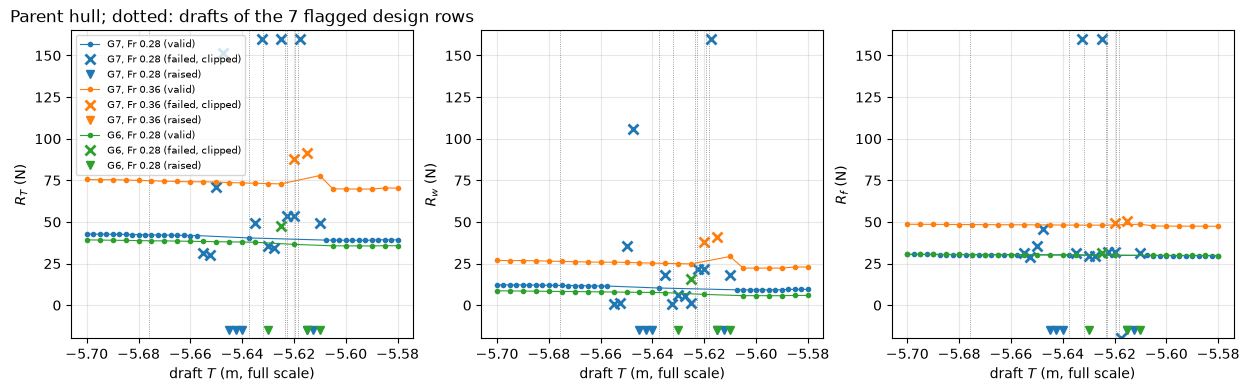

In [5]:
# Draft sweeps at the parent hull (s = 0): draft_sweep.csv columns fidelity, Fr, T, R_T, g1..g4, R_w, R_f,
# S_wet, disp, Rw_wc, Rf_ittc. A run is failed if it raised (NaN) or fails the per-run rule of l2sea_driver.py.
fr_r = lambda r: r[9] / r[13]                                # R_f / R_f,ITTC as the code prints them
def run_fails(r):
    if not np.isfinite(r[3]):
        return 'raised'
    o = dict(zip(gd.l2sea_driver.OUTPUT_NAMES[:-1] + gd.l2sea_driver.DIAG_NAMES, r[3:]))
    return gd.l2sea_driver.failure_reason([r[1], r[2]], o, int(r[0]), band=False)
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for (f, fr), col in zip([(7, 0.28), (7, 0.36), (6, 0.28)], ['C0', 'C1', 'C2']):
    G = SW[(SW[:, 0] == f) & np.isclose(SW[:, 1], fr)]
    why = [run_fails(r) for r in G]
    failed = np.array([w is not None for w in why])
    raised = ~np.isfinite(G[:, 3])
    Tf = G[failed, 2]
    print(f'G{f}, Fr {fr}: {len(G)} drafts {G[:, 2].min():.4f} .. {G[:, 2].max():.4f} m; failed {failed.sum()} '
          f'({raised.sum()} raised, {(failed & ~raised).sum()} returned numbers that fail the rule); '
          + (f'failed drafts {Tf.min():.4f} .. {Tf.max():.4f} m' if failed.any() else 'none failed'))
    ok = ~failed
    if ok.any():
        print(f'    valid runs: R_T {G[ok, 3].min():.3f} .. {G[ok, 3].max():.3f} N, R_f/R_f,ITTC {fr_r(G[ok].T).min():.4f} .. '
              f'{fr_r(G[ok].T).max():.4f}, Rw_wc/R_w {np.min(G[ok, 12] / G[ok, 8]):.3f} .. {np.max(G[ok, 12] / G[ok, 8]):.3f}; '
              f'valid drafts inside the failed range: {np.round(G[ok & (G[:, 2] > Tf.min()) & (G[:, 2] < Tf.max()), 2], 4) if failed.any() else []}')
    Gs = G[np.isfinite(G[:, 3])]
    dS = np.diff(Gs[:, 10]) / np.diff(Gs[:, 2])
    j = int(np.argmin(dS))
    print(f'    largest rate of change of the wetted surface between neighbouring runs: {dS[j]:+.2f} m^2/m between T = '
          f'{Gs[j, 2]:.4f} and {Gs[j + 1, 2]:.4f} m (median {np.median(dS):+.2f} m^2/m)')
    near = (G[:, 2] >= -5.66) & (G[:, 2] <= -5.60)
    print('    R_T (N) for T in [-5.66, -5.60] (* = failed, r = raised): ' + ', '.join(
        f'{t:.4f}: ' + ('r' if not np.isfinite(v) else f'{v:.2f}' + ('*' if fl else '')) for t, v, fl in
        zip(G[near, 2], G[near, 3], failed[near])))
    lab = f'G{f}, Fr {fr}'
    for a, k in zip(axs, (3, 8, 9)):
        a.plot(G[ok, 2], G[ok, k], 'o-', color=col, ms=3, lw=0.8, label=lab + ' (valid)')
        a.plot(G[failed & ~raised, 2], np.clip(G[failed & ~raised, k], -20, 160), 'x', color=col, ms=7, mew=2,
               label=lab + ' (failed, clipped)')
        a.plot(G[raised, 2], np.full(raised.sum(), -15.0), 'v', color=col, ms=6, label=lab + ' (raised)')
for a, t in zip(axs, ('$R_T$ (N)', '$R_w$ (N)', '$R_f$ (N)')):
    a.set_ylim(-20, 165)
    a.set_xlabel('draft $T$ (m, full scale)'); a.set_ylabel(t); a.grid(True, alpha=0.3)
    for t_ in X[bad, 1]:
        a.axvline(t_, color='0.5', lw=0.6, ls=':')
axs[0].legend(fontsize=7, ncol=1)
axs[0].set_title('Parent hull; dotted: drafts of the 7 flagged design rows')
plt.close(fig)
fig

On G7 at Fr = 0.28, **18 of the 49 drafts fail**, every one between −5.655 and −5.610 m: 5 raise and 13 return numbers, some plausible-looking (49.48 N at −5.635 m) and some absurd ($R_T$ up to 96838 N, or a negative $R_f$). Inside that interval only one draft (−5.6375 m) gives a valid run. Outside it the curve is smooth on both sides, but valid values on the two sides differ by a step (41.81 N at −5.6575 m against 39.10 N at −5.6075 m), and the wetted surface changes there at −9.90 m²/m against a median of −0.67 m²/m: the waterline crosses a line of the coarse hull grid, and the free-surface solution breaks down near that crossing. At Fr = 0.36 the band is narrower (2 of 25 drafts fail, at −5.620 and −5.615 m), and the next draft, −5.610 m, returns 77.88 N against 72.86 N and 69.92 N on either side while passing the numerical checks, so a check on the numbers alone is not enough. G6 also fails (4 of 25 drafts, −5.630 to −5.610 m, 3 raised), more narrowly. The band thus depends somewhat on Fr and on the grid; with the hull shape varied (the design rows) it extends to −5.676 m. The rule adopted in `l2sea_driver.failure_reason` treats **every G7 run with $T \in [-5.70, -5.60]$ m and every G6 run with $T \in [-5.65, -5.60]$ m as failed**, in addition to the numerical checks; the band was not mapped for G1–G5.

In [6]:
# Where the flagged rows of the main design lie, how the rule's threshold matters, and what the exclusion does
Tb = X[bad, 1]
print('flagged rows', np.flatnonzero(bad), '; T (m):', np.array2string(np.sort(Tb), precision=4))
print(f'normalized T of the flagged rows {Z[bad, 1].min():.2f} .. {Z[bad, 1].max():.2f}; largest |normalized input| '
      f'per flagged row {np.array2string(np.abs(Z[bad]).max(axis=1), precision=2)} (all rows: median '
      f'{np.median(np.abs(Z).max(axis=1)):.2f})')
wb = (Tb.max() - Tb.min()) / (gd.UPPER[1] - gd.LOWER[1])
nb_ = int(bad.sum())
print(f'their drafts span {100 * wb:.1f} % of the T range; chance that {nb_} independent uniform draws span this little: '
      f'{nb_ * wb ** (nb_ - 1) - (nb_ - 1) * wb ** nb_:.1e}')
lo7, hi7 = gd.l2sea_driver.BAD_T[7]
slab = (X[:, 1] >= lo7) & (X[:, 1] <= hi7)
print(f'design rows with T in the G7 failure band [{lo7}, {hi7}] m of l2sea_driver.py ({100 * (hi7 - lo7) / (gd.UPPER[1] - gd.LOWER[1]):.1f} % '
      f'of the T range): {slab.sum()}, of which flagged {int((slab & bad).sum())}; flagged rows outside it: {np.flatnonzero(bad & ~slab)}')
# sensitivity to the threshold of the friction rule
print(f"{'|z| max':>7s} {'flagged rows':40s} {'lam1/lam2':>9s} {'|w1.w1(8)|':>10s} {'dist2 to 8':>10s}")
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    s8 = ac.active_subspace(space=space, X=X[keep], f=RT[keep], estimator='qphd')
    for zt in (4, 5, 6, 7, 8, 10, 13, 20):
        kz, _ = friction_flags(X, cf_ratio, zt)
        sz_ = ac.active_subspace(space=space, X=X[kz], f=RT[kz], estimator='qphd')
        lam_ = sz_.eigenvalues
        P1, P2 = sz_.eigenvectors[:, :2], s8.eigenvectors[:, :2]
        print(f'{zt:7d} {str(np.flatnonzero(~kz).tolist()):40s} {lam_[0] / lam_[1]:9.2f} '
              f'{abs(sz_.eigenvectors[:, 0] @ s8.eigenvectors[:, 0]):10.4f} {np.linalg.norm(P1 @ P1.T - P2 @ P2.T, 2):10.3f}')
# the per-run rule of l2sea_driver.py (draft band, friction line, wave cut) on the G7 reruns with diagnostics
DG = np.loadtxt('design_diagnostics.csv', delimiter=',')     # row, Rw_wc, Rf_ittc (G7 reruns of 41 rows)
names11 = gd.l2sea_driver.OUTPUT_NAMES[:-1] + gd.l2sea_driver.DIAG_NAMES
fl_nb = [gd.l2sea_driver.failure_reason(X[int(r[0])], dict(zip(names11, list(F[int(r[0])]) + list(r[1:]))), 7, band=False)
         for r in DG]
dg_rows = DG[:, 0].astype(int)
print(f'{len(DG)} rows rerun with diagnostics; the numeric checks of the per-run rule (band test off) flag rows '
      f'{dg_rows[[w is not None for w in fl_nb]]}; the friction rule flags {dg_rows[bad[dg_rows]]}')
# leaving out every row in the band as well
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    kb = keep & ~slab
    sb_ = ac.active_subspace(space=space, X=X[kb], f=RT[kb], estimator='qphd')
print(f'leaving out all {int((~kb).sum())} rows that are flagged or in the band: lambda1/lambda2 = '
      f'{sb_.eigenvalues[0] / sb_.eigenvalues[1]:.2f}, |w1 . w1(8)| = {abs(sb_.eigenvectors[:, 0] @ s8.eigenvectors[:, 0]):.4f}')
# would a residual test on R_T have found them?  robust z against the quadratic of the kept rows
Qall = np.column_stack([np.ones(M), Z] + [Z[:, i] * Z[:, j] for i in range(m) for j in range(i, m)])
cq = np.linalg.lstsq(Qall[keep], RT[keep], rcond=None)[0]
e = RT - Qall @ cq
sc = 1.4826 * np.median(np.abs(e[keep] - np.median(e[keep])))
print('robust z of R_T residuals (quadratic of the kept rows) at the flagged rows:',
      ', '.join(f'{i}: {e[i] / sc:.1f}' for i in np.flatnonzero(bad)))
# does leaving them out skew the design?  centred L2 discrepancy against random subsets of the same size
from scipy.stats import qmc
Ud = (X - gd.LOWER) / (gd.UPPER - gd.LOWER)
rng = np.random.default_rng(SEED)
cd_rand = [qmc.discrepancy(Ud[rng.choice(M, int(keep.sum()), replace=False)], method='CD') for _ in range(100)]
print(f'centred L2 discrepancy: all {M} rows {qmc.discrepancy(Ud, method="CD"):.4f}; kept {int(keep.sum())} rows '
      f'{qmc.discrepancy(Ud[keep], method="CD"):.4f}; random {int(keep.sum())}-row subsets {np.mean(cd_rand):.4f} '
      f'(range {np.min(cd_rand):.4f} .. {np.max(cd_rand):.4f}); largest shift of a normalized input mean '
      f'{np.max(np.abs(Z[keep].mean(0) - Z.mean(0))):.3f}')

flagged rows [  3  63 189 207 305 323 343] ; T (m): [-5.6758 -5.6374 -5.6319 -5.6234 -5.6228 -5.6194 -5.6183]
normalized T of the flagged rows 0.79 .. 0.88; largest |normalized input| per flagged row [0.97 0.99 0.93 0.98 0.96 0.94 0.94] (all rows: median 0.96)
their drafts span 4.7 % of the T range; chance that 7 independent uniform draws span this little: 6.9e-08
design rows with T in the G7 failure band [-5.7, -5.6] m of l2sea_driver.py (8.1 % of the T range): 30, of which flagged 7; flagged rows outside it: []
|z| max flagged rows                             lam1/lam2 |w1.w1(8)| dist2 to 8
      4 [3, 63, 71, 189, 207, 305, 323, 343]         20.29     1.0000      0.053
      5 [3, 63, 71, 189, 207, 305, 323, 343]         20.29     1.0000      0.053
      6 [3, 63, 71, 189, 207, 305, 323, 343]         20.29     1.0000      0.053
      7 [3, 63, 189, 207, 305, 323, 343]             21.63     1.0000      0.000
      8 [3, 63, 189, 207, 305, 323, 343]             21.63     1.0000      0

centred L2 discrepancy: all 384 rows 0.0382; kept 377 rows 0.0401; random 377-row subsets 0.0397 (range 0.0394 .. 0.0400); largest shift of a normalized input mean 0.016


The seven flagged rows span 4.7 % of the draft range (normalized $T$ 0.79–0.88); seven uniform draws fall that close together with probability $6.9\times10^{-8}$, while their largest normalized shape coefficients (0.93–0.99) are typical of any Sobol' point in 16 dimensions (median 0.96). Thirty design rows lie in the G7 band of the rule, all seven flagged rows among them; **the analysis therefore has almost no valid data in the slab where the failures sit** (the 23 kept rows in the band passed the friction check, but nothing guarantees them). Leaving out all 30 changes little ($\lambda_1/\lambda_2 = 20.96$, $|w_1\cdot w_1| = 0.9999$).

The threshold of 8 robust standard deviations was set after seeing the data (the largest kept $|z|$ is 6.5, the next flagged 12.1). Thresholds 7–10 flag the same seven rows; 4–6 add row 71 ($\lambda_1/\lambda_2 = 20.29$, two-dimensional subspace distance 0.053 from the chosen one); 13 drops row 189 (21.73) and 20 keeps only rows 3, 63 and 207 flagged (21.46); $|w_1\cdot w_1|$ is 1.0000 throughout. The numerical checks of the per-run rule, applied to 41 G7 reruns that also record the wave-cut wave resistance and the code's ITTC friction (`design_diagnostics.csv`, identical outputs), flag exactly the same seven rows. A residual test on $R_T$ would not have found most of them: against the quadratic of the kept rows rows 189, 323 and 343 have robust $z$ of 0.6, −0.3 and −2.3. The exclusion thins one slab of draft rather than distorting the design as a whole: the centred $L_2$ discrepancy of the 377 kept rows is 0.0401, just above the 0.0394–0.0400 of 100 random 377-row subsets (1 % above their mean of 0.0397), and no normalized input mean moves by more than 0.016.

### Estimate the subspace

The code gives no gradients, and finite differences would cost 17 runs per gradient, so we use the library's **global quadratic estimator** (`estimator="qphd"`): it fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ by least squares on the 153 monomials of degree ≤ 2 in the 16 normalized inputs and returns $\mathbf C = \mathbf g\mathbf g^T + \tfrac13\mathbf H^2$, which is $\mathbb E[\nabla q\,\nabla q^T]$ for the uniform density on the cube [[3]](https://doi.org/10.1137/1.9781611973860). With 377 runs the fit has 2.46 runs per coefficient (a common rule of thumb asks for at least two). The library warns (`ValidityWarning`, silenced) that reading $\mathbf g$ and $\mathbf H$ as the average gradient and Hessian of $f$ itself assumes Gaussian inputs; the matrix is still the active subspace of the fitted quadratic, and the cell after next checks it against least squares (OLS) and local linear gradients (OPG). The bootstrap resamples the 377 runs 500 times with one seed (`SEED`) and keeps the first two eigenvectors of every replicate; $w_1$ is signed so that $w_1^T\mathbf x$ increases with the output (`ac.orient(by="covariance")`). Both $R_T$ and the wave resistance $R_w$ are analyzed.

In [7]:
Xk, RTk, Rwk, Zk, Mk = X[keep], RT[keep], Rw[keep], Z[keep], int(keep.sum())
res = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    for q, f in [('R_T', RTk), ('R_w', Rwk)]:
        s = ac.active_subspace(space=space, X=Xk, f=f, estimator='qphd', nboot=500,
                               bootstrap_vectors=2, rng=SEED)
        res[q] = ac.orient(s, by='covariance', X=Xk, f=f)
    s_all = ac.active_subspace(space=space, X=X, f=RT, estimator='qphd')
for q in res:
    s = res[q]
    lam = s.eigenvalues
    lo, hi = np.percentile(s.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
    ks, crit, khat = ac.dimension_criterion(s, rule='evg')
    print(f'{q}: QPHD with M = {Mk} runs for {(m + 1) * (m + 2) // 2} coefficients '
          f'({Mk / ((m + 1) * (m + 2) / 2):.2f} runs per coefficient); eigenvalue-gap rule n = {s.n}')
    print('   lambda_1..6        ', np.array2string(lam[:6], precision=4))
    print('   95 % bootstrap low ', np.array2string(lo[:6], precision=4))
    print('   95 % bootstrap high', np.array2string(hi[:6], precision=4))
    print(f'   lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}; '
          f'share of trace in lambda1 {lam[0] / lam.sum():.4f}')
la = s_all.eigenvalues
print(f'R_T with the flagged rows kept: lambda1/lambda2 = {la[0] / la[1]:.2f}, '
      f'|w1 . w1(kept rows)| = {abs(s_all.eigenvectors[:, 0] @ res["R_T"].eigenvectors[:, 0]):.4f}')

R_T: QPHD with M = 377 runs for 153 coefficients (2.46 runs per coefficient); eigenvalue-gap rule n = 1
   lambda_1..6         [2568.9059  118.7453   74.454    22.4164   18.3539   17.1985]
   95 % bootstrap low  [2435.3157   97.6836   55.4466   30.8598   23.0971   17.4997]
   95 % bootstrap high [2726.9363  211.5467  142.7807   79.2305   59.0355   43.7518]
   lambda1/lambda2 = 21.6, lambda2/lambda3 = 1.59; share of trace in lambda1 0.8980
R_w: QPHD with M = 377 runs for 153 coefficients (2.46 runs per coefficient); eigenvalue-gap rule n = 1
   lambda_1..6         [981.1784 108.229   66.5602  19.2912  18.4579  13.2783]
   95 % bootstrap low  [902.0394  88.2765  50.2836  28.7248  21.5789  16.5187]
   95 % bootstrap high [1103.5942  194.4097  130.7462   73.8046   56.2785   42.4851]
   lambda1/lambda2 = 9.1, lambda2/lambda3 = 1.63; share of trace in lambda1 0.7883
R_T with the flagged rows kept: lambda1/lambda2 = 4.99, |w1 . w1(kept rows)| = 0.9965


For $R_T$ the first eigenvalue is 21.6 times the second and carries 0.898 of the trace; its 95 % bootstrap range $[2435, 2727]$ is far from that of $\lambda_2$, $[97.7, 211.5]$. After it the spectrum is flat: $\lambda_2/\lambda_3 = 1.59$, with overlapping bootstrap ranges for $\lambda_2$ and $\lambda_3$ ($[55.4, 142.8]$). The eigenvalue-gap rule picks $n = 1$, and we use **one active variable for $R_T$**: $\lambda_1/\lambda_2$ is the only large gap, and the next cells show that only the one-dimensional subspace is well determined by the bootstrap. The `AccuracyWarning` says the same about the second eigenvector: its bootstrap replicates are poorly aligned with it, so $w_2$ is not well determined. Keeping the 7 flagged runs would lower $\lambda_1/\lambda_2$ to 4.99 while barely moving $w_1$ ($|w_1\cdot w_1| = 0.9965$): the failed solves add spurious variation in other directions. The bootstrap ranges of the small eigenvalues lie entirely above the estimates ($\lambda_4 = 22.4$ with range $[30.9, 79.2]$, and likewise $\lambda_5$ and $\lambda_6$): resampling the runs biases the small eigenvalues of a fitted quadratic upward, so these ranges do not cover the estimates and are not used; the conclusions rest on $\lambda_1$–$\lambda_3$. The wave resistance has the same structure with a smaller gap ($\lambda_1/\lambda_2 = 9.1$, $\lambda_2/\lambda_3 = 1.63$).

In [8]:
chk = {}
for q, f in [('R_T', RTk), ('R_w', Rwk)]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        ols = ac.active_subspace(space=space, X=Xk, f=f, estimator='ols', n=1)
        opg = ac.active_subspace(space=space, X=Xk, f=f, estimator='opg', n=2)
    A = np.column_stack([np.ones(Mk), Zk])
    coef, *_ = np.linalg.lstsq(A, f, rcond=None)
    r = f - A @ coef
    lin_r2 = 1 - r @ r / ((f - f.mean()) @ (f - f.mean()))
    w = res[q].eigenvectors
    P = opg.eigenvectors[:, :2]
    chk[q] = dict(ols=ols, opg=opg, lin_r2=lin_r2)
    Q = np.column_stack([A] + [Zk[:, i] * Zk[:, j] for i in range(m) for j in range(i, m)])
    cq, *_ = np.linalg.lstsq(Q, f, rcond=None)
    rq = f - Q @ cq
    loo = rq / (1 - np.einsum('ij,ji->i', Q, np.linalg.pinv(Q)))
    zl = (loo - np.median(loo)) / (1.4826 * np.median(np.abs(loo - np.median(loo))))
    print(f'{q}: global quadratic R^2 {1 - rq @ rq / ((f - f.mean()) @ (f - f.mean())):.4f} '
          f'(RMS residual {np.sqrt(np.mean(rq ** 2)):.2f} N); largest robust z of its LOO residuals {np.abs(zl).max():.1f}')
    print(f'{q}: linear fit R^2 {lin_r2:.4f}; |w1 . w_ols| {abs(w[:, 0] @ ols.eigenvectors[:, 0]):.4f}; '
          f'|w1 . w1_opg| {abs(w[:, 0] @ P[:, 0]):.4f}; span(w1, w2) vs OPG, principal-angle cosines '
          f'{np.array2string(np.linalg.svd(w[:, :2].T @ P)[1], precision=4)}')

R_T: global quadratic R^2 0.9878 (RMS residual 3.16 N); largest robust z of its LOO residuals 3.9
R_T: linear fit R^2 0.9236; |w1 . w_ols| 0.9994; |w1 . w1_opg| 0.9979; span(w1, w2) vs OPG, principal-angle cosines [0.999  0.8716]
R_w: global quadratic R^2 0.9686 (RMS residual 3.11 N); largest robust z of its LOO residuals 3.9
R_w: linear fit R^2 0.8342; |w1 . w_ols| 0.9964; |w1 . w1_opg| 0.9916; span(w1, w2) vs OPG, principal-angle cosines [0.997  0.8682]


The global quadratic fits $R_T$ with $R^2 = 0.9878$ (RMS residual 3.16 N) and $R_w$ with 0.9686, and no kept run stands out from it (largest robust $z$ of the leave-one-out residuals 3.9 for both), so the friction rule has not missed gross failures. The three estimators agree on the first direction: $|w_1\cdot w_{ols}| = 0.9994$ and $|w_1\cdot w_{1,opg}| = 0.9979$ for $R_T$ (0.9964 and 0.9916 for $R_w$), and a linear model alone explains $R^2 = 0.9236$ of $R_T$. The second directions agree less well (principal-angle cosine 0.8716 for $R_T$), as expected from the small second gap.

### Results: total resistance $R_T$

**Eigenvalues and subspace errors.** Left: eigenvalues with the 95 % bootstrap band. Right: the bootstrap mean of the distance between the estimated and replicate subspaces for each dimension $k$.

Total resistance $R_T$: mean bootstrap subspace distance, k = 1..4: [0.0465 0.4714 0.4693 0.8762]


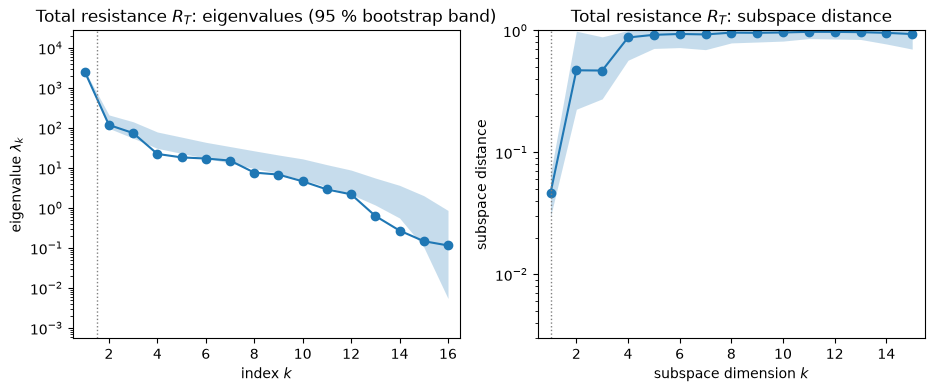

In [9]:
def eig_err_figure(s, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    ac.plotting.plot_eigenvalues(s, ax=a1)
    a1.set_title(f'{title}: eigenvalues (95 % bootstrap band)')
    ac.plotting.plot_subspace_errors(s, ax=a2)
    a2.set_title(f'{title}: subspace distance')
    plt.close(fig)
    d = ac.mean_distance(s)
    print(f'{title}: mean bootstrap subspace distance, k = 1..4:', np.array2string(d[:4], precision=4))
    return fig


fig = eig_err_figure(res['R_T'], 'Total resistance $R_T$')
fig

One eigenvalue stands out and the one-dimensional subspace is well determined (mean bootstrap distance 0.0465), while the two- and three-dimensional subspaces are not (0.4714 and 0.4693): the second and third eigenvalues are too close to separate their eigenvectors.

**Eigenvectors.** $w_1$ and $w_2$ with their 95 % bootstrap bands (normalized inputs, so a component is the effect of moving that input across its whole range).

$R_T$ w1: Fr +0.959, T -0.239, s2 +0.125, s13 +0.044; sum of squares of the 14 shape components 0.0224
$R_T$ w2: s2 +0.666, s1 +0.525, s3 -0.316, s4 +0.286; sum of squares of the 14 shape components 0.9703


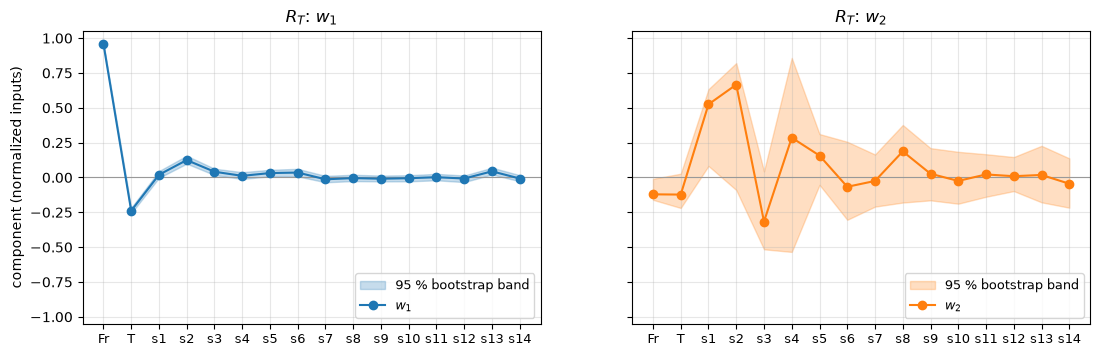

In [10]:
def vec_figure(s, title):
    W = s.eigenvectors
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
    k = np.arange(m)
    for i in range(2):
        B = s.bootstrap_eigenvectors[:, :, i]
        lo, hi = np.percentile(B, [2.5, 97.5], axis=0)
        axs[i].axhline(0, color='0.6', lw=0.8)
        axs[i].fill_between(k, lo, hi, color=f'C{i}', alpha=0.25, label='95 % bootstrap band')
        axs[i].plot(k, W[:, i], 'o-', color=f'C{i}', label=f'$w_{i + 1}$')
        axs[i].set_xticks(k, labels, rotation=0, fontsize=9)
        axs[i].grid(True, alpha=0.3)
        axs[i].legend(loc='lower right', fontsize=9)
        axs[i].set_title(f'{title}: $w_{i + 1}$')
    axs[0].set_ylim(-1.05, 1.05)
    axs[0].set_ylabel('component (normalized inputs)')
    plt.close(fig)
    for i in range(2):
        order = np.argsort(-np.abs(W[:, i]))[:4]
        print(f'{title} w{i + 1}: ' + ', '.join(f'{labels[j]} {W[j, i]:+.3f}' for j in order)
              + f'; sum of squares of the 14 shape components {np.sum(W[2:, i] ** 2):.4f}')
    return fig


fig = vec_figure(res['R_T'], '$R_T$')
fig

The first direction is the speed: Fr has weight 0.959 and the draft −0.239 (a deeper hull, more negative $T$, has more resistance), while the 14 shape modes together carry only 0.0224 of its squared length, mostly mode 2 (0.125). Over this box, then, the operating condition moves $R_T$ in newtons far more than the hull shape does; the cells after the sufficient summary plots show that this is mostly the speed scaling of resistance, not a statement about the hull's hydrodynamic efficiency. (The paper poses its UQ benchmark in Fr and T and its optimization benchmark in the shape at fixed Fr and T; it does not say why, and we do not read this result as the reason.) The second direction is almost all shape (0.9703 of its squared length), with its largest components on modes 2, 1, 3 and 4 (0.666, 0.525, −0.316, 0.286), but it is **not well determined**: its bootstrap bands are wide, the mean bootstrap distance of the two-dimensional subspace is 0.4714, and the shape-only study below finds different shape directions.

**Sufficient summary plots.** $R_T$ against $y_1 = w_1^T\mathbf x$ (left) and against $(y_1, y_2)$ (right).

y1 range [-1.190, 1.180], y2 range [-1.526, 1.618]; parent hull at Fr = 0.28, T = -6.16: (y1, y2) = (-0.600, 0.076)
polynomial of degree 1 in y1 alone: in-sample R^2 0.9225
polynomial of degree 2 in y1 alone: in-sample R^2 0.9508
polynomial of degree 3 in y1 alone: in-sample R^2 0.9514
correlation of R_T with Fr alone: 0.9172 (R^2 of a straight line in Fr 0.8413)


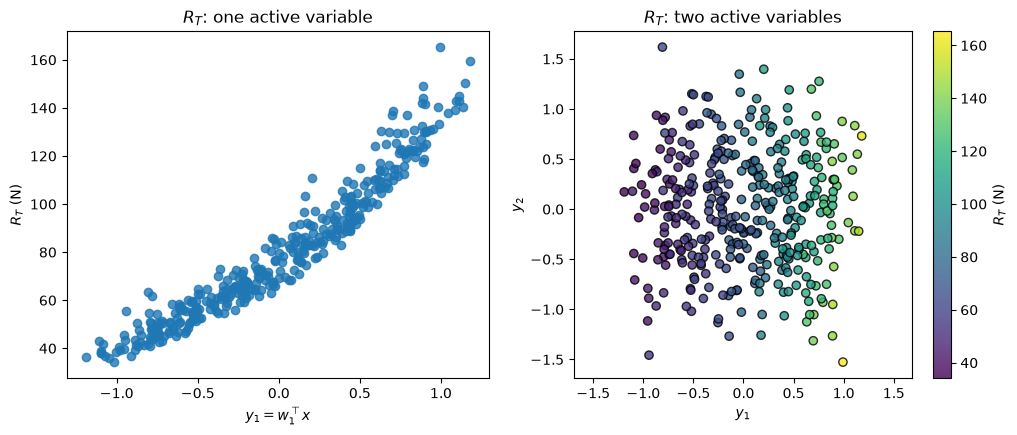

In [11]:
s = res['R_T']
W = s.eigenvectors
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(s, X=Xk, f=RTk, dims=1, qoi_label='$R_T$ (N)', ax=a1)
ac.plotting.plot_sufficient_summary(s, X=Xk, f=RTk, dims=2, qoi_label='$R_T$ (N)', ax=a2,
                                    scatter_kw={'cmap': 'viridis', 'edgecolors': 'k'})
z0 = 2 * (gd.NOMINAL - gd.LOWER) / (gd.UPPER - gd.LOWER) - 1
a1.set_title('$R_T$: one active variable'); a2.set_title('$R_T$: two active variables')
plt.close(fig)
Y = Zk @ W[:, :2]
print(f'y1 range [{Y[:, 0].min():.3f}, {Y[:, 0].max():.3f}], y2 range [{Y[:, 1].min():.3f}, {Y[:, 1].max():.3f}]; '
      f'parent hull at Fr = 0.28, T = -6.16: (y1, y2) = ({z0 @ W[:, 0]:.3f}, {z0 @ W[:, 1]:.3f})')
for deg in (1, 2, 3):
    c = np.polyfit(Y[:, 0], RTk, deg)
    r = RTk - np.polyval(c, Y[:, 0])
    print(f'polynomial of degree {deg} in y1 alone: in-sample R^2 {1 - r @ r / ((RTk - RTk.mean()) @ (RTk - RTk.mean())):.4f}')
rFr = np.corrcoef(Zk[:, 0], RTk)[0, 1]
print(f'correlation of R_T with Fr alone: {rFr:.4f} (R^2 of a straight line in Fr {rFr ** 2:.4f})')
fig

$R_T$ rises steeply and almost monotonically with $y_1$, with a mild upward curvature: a straight line in $y_1$ explains $R^2 = 0.9225$, a quadratic 0.9508 and a cubic 0.9514, against 0.8413 for a straight line in Fr alone, so the draft term in $w_1$ matters. The spread about the curve (the remaining 5 %) comes from the other directions; in the right panel the colour changes almost only along $y_1$, and the effect of $y_2$ is too small to see on this colour scale (the surrogates below measure it). The parent hull at Fr = 0.28, T = −6.16 lies at $(y_1, y_2) = (-0.600, 0.076)$.

### How much of this is speed scaling? The resistance coefficient

Resistance grows roughly with the square of the speed, $R_T \approx \tfrac12\rho U^2 S\,C_T$ with $U = \mathrm{Fr}\sqrt{gL_{pp}}$, so a large Fr weight in $w_1$ is expected whatever the hull. The next cell repeats the analysis for the dimensionless **total-resistance coefficient** $C_T = R_T/(\tfrac12\rho U^2 S)$ (with the run's wetted surface $S$; values ×1000), and for $\log R_T$, on the same 377 runs, estimator and seed.

C_T x 1000: range 3.900 .. 7.160; eigenvalue-gap rule n = 1
   lambda_1..5         [0.7929 0.4233 0.2608 0.1247 0.0693]
   95 % bootstrap low  [0.7315 0.3545 0.2128 0.1272 0.0847]
   95 % bootstrap high [1.1072 0.7311 0.4512 0.2924 0.209 ]
   lambda1/lambda2 = 1.87, lambda2/lambda3 = 1.62; mean bootstrap subspace distance k = 1..3: [0.25  0.447 0.51 ]
   w1(C_T): s2 +0.626, Fr +0.562, T -0.437, s1 +0.178, s4 +0.162; |w1(C_T) . w1(R_T)| = 0.7366
   global quadratic R^2 for C_T: 0.9080
log R_T: lambda1/lambda2 = 24.3, |w1(log R_T) . w1(R_T)| = 0.9990


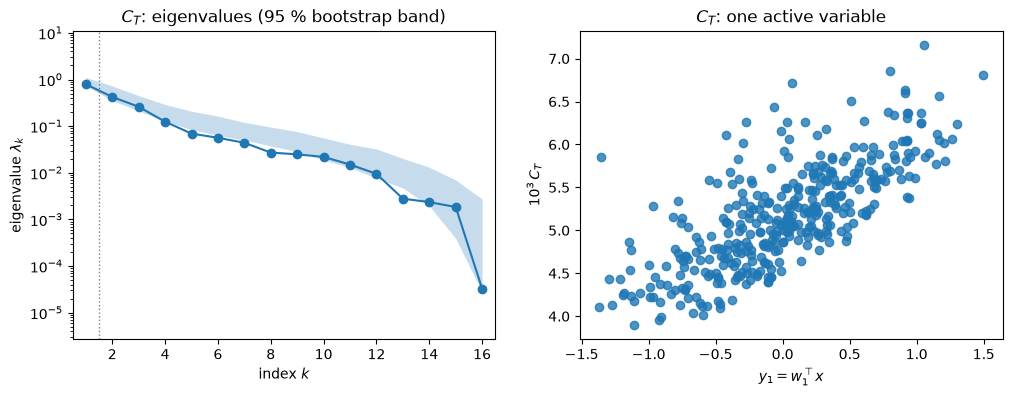

In [12]:
# dimensionless total-resistance coefficient C_T = R_T / (0.5 rho U^2 S), U = Fr sqrt(g Lpp), S = wetted surface
CT = RT / (0.5 * rho * U ** 2 * out['S_wet'])
CTk = CT[keep]
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    sCT = ac.active_subspace(space=space, X=Xk, f=1e3 * CTk, estimator='qphd', nboot=500,
                             bootstrap_vectors=2, rng=SEED)
    sCT = ac.orient(sCT, by='covariance', X=Xk, f=CTk)
    slog = ac.active_subspace(space=space, X=Xk, f=np.log(RTk), estimator='qphd')
lam = sCT.eigenvalues
lo, hi = np.percentile(sCT.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print(f'C_T x 1000: range {1e3 * CTk.min():.3f} .. {1e3 * CTk.max():.3f}; eigenvalue-gap rule n = {sCT.n}')
print('   lambda_1..5        ', np.array2string(lam[:5], precision=4))
print('   95 % bootstrap low ', np.array2string(lo[:5], precision=4))
print('   95 % bootstrap high', np.array2string(hi[:5], precision=4))
print(f'   lambda1/lambda2 = {lam[0] / lam[1]:.2f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}; '
      f'mean bootstrap subspace distance k = 1..3: {np.array2string(ac.mean_distance(sCT)[:3], precision=3)}')
Wc = sCT.eigenvectors
order = np.argsort(-np.abs(Wc[:, 0]))[:5]
print('   w1(C_T): ' + ', '.join(f'{labels[j]} {Wc[j, 0]:+.3f}' for j in order)
      + f'; |w1(C_T) . w1(R_T)| = {abs(Wc[:, 0] @ res["R_T"].eigenvectors[:, 0]):.4f}')
Qc = np.column_stack([np.ones(Mk), Zk] + [Zk[:, i] * Zk[:, j] for i in range(m) for j in range(i, m)])
rc = CTk - Qc @ np.linalg.lstsq(Qc, CTk, rcond=None)[0]
print(f'   global quadratic R^2 for C_T: {1 - rc @ rc / ((CTk - CTk.mean()) @ (CTk - CTk.mean())):.4f}')
ll = slog.eigenvalues
print(f'log R_T: lambda1/lambda2 = {ll[0] / ll[1]:.1f}, '
      f'|w1(log R_T) . w1(R_T)| = {abs(slog.eigenvectors[:, 0] @ res["R_T"].eigenvectors[:, 0]):.4f}')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
ac.plotting.plot_eigenvalues(sCT, ax=a1)
a1.set_title('$C_T$: eigenvalues (95 % bootstrap band)')
ac.plotting.plot_sufficient_summary(sCT, X=Xk, f=1e3 * CTk, dims=1, qoi_label='$10^3\\,C_T$', ax=a2)
a2.set_title('$C_T$: one active variable')
plt.close(fig)
fig

On $\log R_T$ the gap is about the same ($\lambda_1/\lambda_2 = 24.3$, $|w_1\cdot w_1| = 0.9990$), but on $C_T$ **it disappears**: $\lambda_1/\lambda_2 = 1.87$ and $\lambda_2/\lambda_3 = 1.62$, the bootstrap ranges of $\lambda_1$ ($[0.73, 1.11]$) and $\lambda_2$ ($[0.35, 0.73]$) almost touch, and the mean bootstrap distance of the one-dimensional subspace is 0.25. The leading direction of $C_T$ mixes shape and operating condition (s2 +0.626, Fr +0.562, T −0.437, s1 +0.178, s4 +0.162; $|w_1(C_T)\cdot w_1(R_T)| = 0.7366$), and a global quadratic explains less of it ($R^2 = 0.9080$). So the one-dimensional result for $R_T$ is true of the resistance in newtons over this box, and is mostly the $U^2$ scaling; once that is divided out, speed, draft and the leading shape modes matter comparably, and no single direction dominates.

**What the 16-input design says about the shape.** The shape directions are what the optimization benchmark is about. The 14 × 14 shape block of the quadratic's matrix, $\mathbb E[\nabla_{\mathbf s} q\,\nabla_{\mathbf s} q^T]$ over the box, and the same matrix with Fr and T held at the benchmark's 0.28 and −6.16, are computed below from the same fit, with a 300-replicate bootstrap of the 377 runs (seed `SEED`).

In [13]:
# The shape part of the 16-input quadratic: C = g g^T + H^2 / 3 (uniform on [-1, 1]^16), its 14 x 14 block
# for s1..s14 (= E[grad_s q grad_s q^T] over the box), and the same at Fr = 0.28, T = -6.16 held
iu = [(i, j) for i in range(m) for j in range(i, m)]
def quad_fit(Zs, f):
    Q = np.column_stack([np.ones(len(Zs)), Zs] + [Zs[:, i] * Zs[:, j] for i, j in iu])
    c = np.linalg.lstsq(Q, f, rcond=None)[0]
    d = Zs.shape[1]
    H = np.zeros((d, d))
    for (i, j), v in zip(iu, c[d + 1:]):
        H[i, j] = H[j, i] = (2 * v if i == j else v)
    return c[0], c[1:d + 1], H

def eigsort(C):
    lam, W = np.linalg.eigh(C)
    return lam[::-1], W[:, ::-1]

zc = z0[:2]                                                  # normalized (Fr, T) of the benchmark point
def shape_blocks(Zs, f):
    c0, gq, H = quad_fit(Zs, f)
    C = np.outer(gq, gq) + H @ H / 3
    gs = gq[2:] + H[2:, :2] @ zc
    return C, C[2:, 2:], np.outer(gs, gs) + H[2:, 2:] @ H[2:, 2:] / 3, (c0, gq, H)

C16, Cb, Cc, (c0, gq, Hq) = shape_blocks(Zk, RTk)
print(f'check: eigenvalues of g g^T + H^2/3 = {np.array2string(eigsort(C16)[0][:3], precision=1)} '
      f'(library QPHD {np.array2string(res["R_T"].eigenvalues[:3], precision=1)})')
rng = np.random.default_rng(SEED)
boot = {'block': [], 'cond': []}
blk = {'block': eigsort(Cb), 'cond': eigsort(Cc)}
for b in range(300):
    i = rng.integers(0, Mk, Mk)
    _, Cb_b, Cc_b, _ = shape_blocks(Zk[i], RTk[i])
    for key, Cx in (('block', Cb_b), ('cond', Cc_b)):
        Wb = eigsort(Cx)[1]
        W0 = blk[key][1]
        boot[key].append([np.linalg.norm(W0[:, :k] @ W0[:, :k].T - Wb[:, :k] @ Wb[:, :k].T, 2) for k in (1, 2)])
for key, title in (('block', 'shape block over the box'), ('cond', 'at Fr = 0.28, T = -6.16')):
    lam, W = blk[key]
    w = W[:, 0] * np.sign(W[np.argmax(np.abs(W[:, 0])), 0])
    o = np.argsort(-np.abs(w))[:4]
    print(f'{title}: lambda_1..4 {np.array2string(lam[:4], precision=1)}; ratios {lam[0] / lam[1]:.2f}, {lam[1] / lam[2]:.2f}; '
          f'mean bootstrap distance (300 replicates) k = 1, 2: {np.array2string(np.mean(boot[key], axis=0), precision=2)}')
    print('    w1: ' + ', '.join(f'{labels[2 + j]} {w[j]:+.3f}' for j in o))
wblock = blk['block'][1][:, 0]
print(f'|w1(shape block) . w2(R_T) restricted to s, normalized| = '
      f'{abs(wblock @ res["R_T"].eigenvectors[2:, 1]) / np.linalg.norm(res["R_T"].eigenvectors[2:, 1]):.3f}')
q_parent = c0 + gq @ z0 + 0.5 * z0 @ Hq @ z0
RT_parent7 = REF[(REF[:, 0] == 0) & (REF[:, 1] == 7), 18][0]
print(f'the 16-input quadratic at the parent hull: {q_parent:.2f} N against {RT_parent7:.2f} N on G7 '
      f'({100 * (q_parent / RT_parent7 - 1):+.1f} %)')

check: eigenvalues of g g^T + H^2/3 = [2568.9  118.7   74.5] (library QPHD [2568.9  118.7   74.5])


shape block over the box: lambda_1..4 [145.5  80.8  36.7  19. ]; ratios 1.80, 2.20; mean bootstrap distance (300 replicates) k = 1, 2: [0.36 0.45]
    w1: s2 +0.833, s1 +0.431, s5 +0.192, s8 +0.158
at Fr = 0.28, T = -6.16: lambda_1..4 [148.7  74.5  34.8  20.9]; ratios 2.00, 2.14; mean bootstrap distance (300 replicates) k = 1, 2: [0.38 0.49]
    w1: s2 +0.763, s1 +0.480, s4 +0.322, s3 -0.203
|w1(shape block) . w2(R_T) restricted to s, normalized| = 0.935
the 16-input quadratic at the parent hull: 44.01 N against 48.93 N on G7 (-10.1 %)


The shape block has eigenvalues 145.5, 80.8, 36.7, 19.0 (ratios 1.80 and 2.20) and leading direction s2 +0.833, s1 +0.431, s5 +0.192, s8 +0.158; at Fr = 0.28, T = −6.16 the ratios are 2.00 and 2.14. Its one-dimensional subspace has a mean bootstrap distance of 0.36 (0.38 at the benchmark point), so **the 16-input design does not determine the shape subspace**. The global quadratic also misses the parent hull itself by −10.1 % (44.01 N against 48.93 N on G7): fitted over the whole box, it is not accurate at a fixed operating point. The shape-only study below answers the shape question directly.

### Results: wave resistance $R_w$

The frictional part of $R_T$ depends on the hull shape only through the wetted surface, so the shape modes act mainly through the wave resistance. The same analysis for $R_w$: eigenvalues, eigenvectors and sufficient summary plots.

Wave resistance $R_w$: mean bootstrap subspace distance, k = 1..4: [0.0819 0.475  0.4865 0.8684]


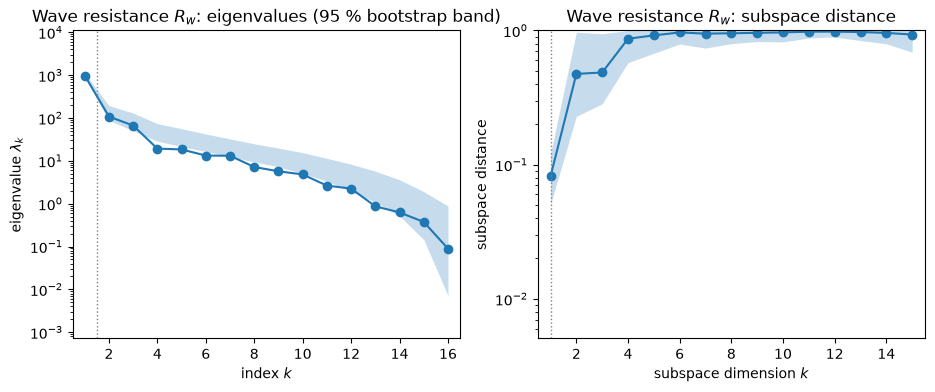

In [14]:
fig = eig_err_figure(res['R_w'], 'Wave resistance $R_w$')
fig

$R_w$ w1: Fr +0.932, T -0.276, s2 +0.203, s13 +0.062; sum of squares of the 14 shape components 0.0543
$R_w$ w2: s2 +0.630, s1 +0.527, s4 +0.339, s3 -0.308; sum of squares of the 14 shape components 0.9393
|w1(R_w) . w1(R_T)| = 0.9951; span(w1, w2) of R_w vs that of R_T: cosines 0.9978, 0.9953


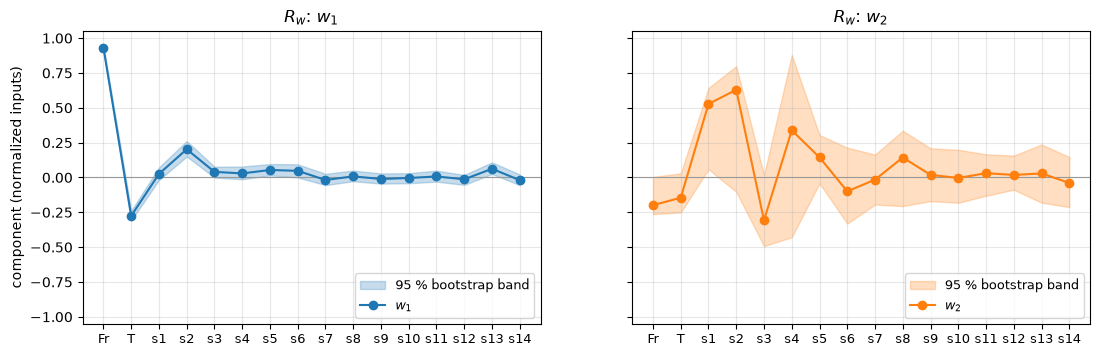

In [15]:
fig = vec_figure(res['R_w'], '$R_w$')
cosRT = np.linalg.svd(res['R_w'].eigenvectors[:, :2].T @ res['R_T'].eigenvectors[:, :2])[1]
print(f'|w1(R_w) . w1(R_T)| = {abs(res["R_w"].eigenvectors[:, 0] @ res["R_T"].eigenvectors[:, 0]):.4f}; '
      f'span(w1, w2) of R_w vs that of R_T: cosines {cosRT[0]:.4f}, {cosRT[1]:.4f}')
fig

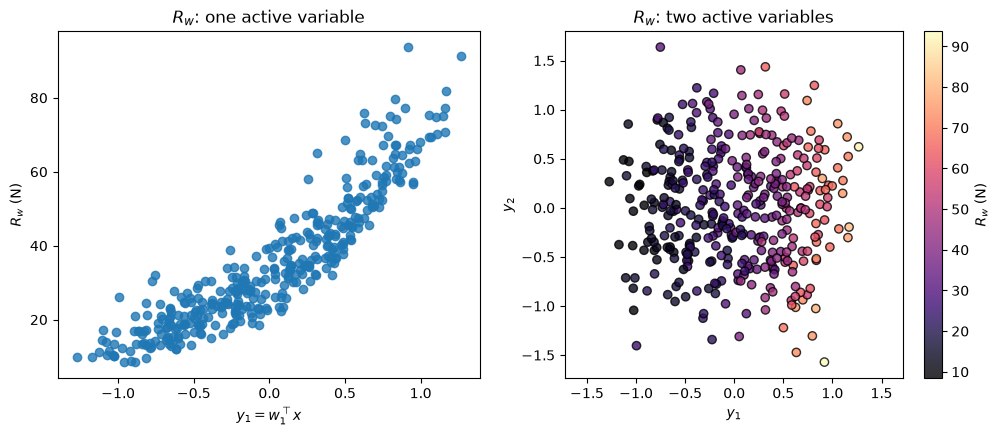

In [16]:
sw = res['R_w']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sw, X=Xk, f=Rwk, dims=1, qoi_label='$R_w$ (N)', ax=a1)
ac.plotting.plot_sufficient_summary(sw, X=Xk, f=Rwk, dims=2, qoi_label='$R_w$ (N)', ax=a2,
                                    scatter_kw={'cmap': 'magma', 'edgecolors': 'k'})
a1.set_title('$R_w$: one active variable'); a2.set_title('$R_w$: two active variables')
plt.close(fig)
fig

The wave resistance has the same first direction as $R_T$ ($|w_1\cdot w_1| = 0.9951$; Fr 0.932, T −0.276) with a larger share for the shape modes (0.0543 of the squared length, mode 2 at 0.203), and a second direction of the same shape modes (2, 1, 4, 3; as poorly determined as for $R_T$), so the two-dimensional subspaces of $R_w$ and $R_T$ coincide (principal-angle cosines 0.9978 and 0.9953). The gap is smaller ($\lambda_1/\lambda_2 = 9.1$) because the frictional part, which follows Fr closely, is removed; the shape modes act on the resistance mainly through the waves, as expected from the physics of the model.

### Surrogates on the active variables

Polynomials of degree $k$ in $n$ active variables, with in-sample and leave-one-out (LOO) $R^2$. The subspaces are held fixed at the quadratic estimates, so the LOO values do not include the error of estimating them. The plot shows the cubic in two variables for $R_T$.

QoI   n degree     R^2  LOO R^2
R_T   1      2  0.9508   0.9500
R_T   1      3  0.9514   0.9504
R_T   1      4  0.9516   0.9503
R_T   2      2  0.9671   0.9658
R_T   2      3  0.9727   0.9702
R_T   3      2  0.9757   0.9740
R_w   1      2  0.8750   0.8731
R_w   1      3  0.8754   0.8730
R_w   1      4  0.8765   0.8733
R_w   2      2  0.9164   0.9129
R_w   2      3  0.9284   0.9225
R_w   3      2  0.9365   0.9320
cubic in two variables for R_T: RMS residual 4.719 N (5.84 % of the mean R_T)


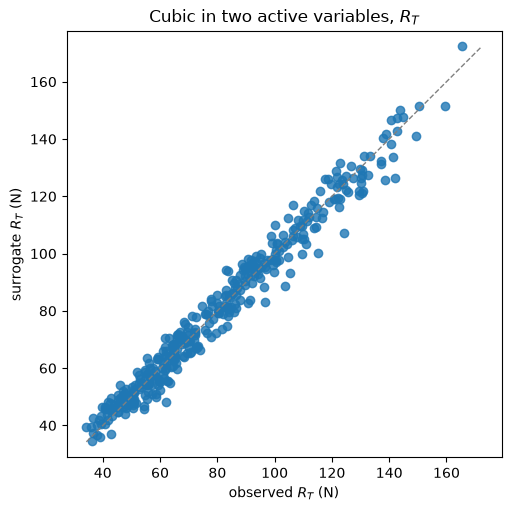

In [17]:
rows = []
for q, f in [('R_T', RTk), ('R_w', Rwk)]:
    for n, deg in [(1, 2), (1, 3), (1, 4), (2, 2), (2, 3), (3, 2)]:
        sg = ac.fit_surrogate(X=Xk, f=f, subspace=ac.with_dimension(res[q], n=n), kind='poly', degree=deg)
        r2 = 1 - sg.residuals @ sg.residuals / ((f - f.mean()) @ (f - f.mean()))
        rows.append((q, n, deg, r2, sg.loo_r_squared))
        if (q, n, deg) == ('R_T', 2, 3):
            sur = sg
print(f"{'QoI':4s} {'n':>2s} {'degree':>6s} {'R^2':>7s} {'LOO R^2':>8s}")
for q, n, deg, r2, loo in rows:
    print(f'{q:4s} {n:2d} {deg:6d} {r2:7.4f} {loo:8.4f}')
R2 = {(q, n, d): (r2, loo) for q, n, d, r2, loo in rows}
print(f'cubic in two variables for R_T: RMS residual {np.sqrt(np.mean(sur.residuals ** 2)):.3f} N '
      f'({np.sqrt(np.mean(sur.residuals ** 2)) / RTk.mean() * 100:.2f} % of the mean R_T)')
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=Xk, f=RTk, qoi_label='$R_T$ (N)', figsize=(5, 5))
ax.set_title('Cubic in two active variables, $R_T$')
plt.close(fig)
fig

One active variable gives LOO $R^2 = 0.9500$ for $R_T$ with a quadratic, and higher degrees add nothing (0.9504 for a cubic). A second variable raises the LOO $R^2$ to 0.9702 (cubic) and a third to 0.9740 (quadratic), so the shape directions carry real but small effects; the cubic in two variables leaves an RMS residual of 4.72 N, 5.84 % of the mean $R_T$. For $R_w$ the gain from more variables is larger (LOO 0.8731 → 0.9225 → 0.9320), in line with its smaller eigenvalue gap. The global quadratic in all 16 inputs reaches 0.9878 in-sample for $R_T$, so most of the 4.9 % that a quadratic in one active variable misses is smooth variation in other directions (shape modes and interactions), not noise.

### Second study: the hull shape alone (Fr = 0.28, T = −6.16)

**Design.** The optimization benchmark of App. A.4.1 (p. 32) fixes "Fr = 0.28 and nominal draft T = −6.16" and varies only the 14 shape coefficients in $[-1, 1]$. This study does the same with $\mathbf s$ uniform on $[-1, 1]^{14}$: the first 256 points of a 14-dimensional scrambled Sobol' sequence (`scipy.stats.qmc.Sobol`, seed 14), all on G7 (`shape_inputs.csv`, `shape_outputs.csv`, which also hold the two diagnostics). T = −6.16 m is far from the failure band; the same friction rule and the per-run rule are applied anyway. QPHD fits $(14 + 1)(14 + 2)/2 = 120$ coefficients, so 256 runs give 2.13 per coefficient (a common rule of thumb asks for at least two). The space is 14 uniforms on $[-1, 1]$; seed, bootstrap and sign rule as in the main study.

In [18]:
# Second study: s1..s14 on [-1, 1]^14 at Fr = 0.28, T = -6.16, G7 (shape_inputs.csv, shape_outputs.csv)
ms = 14
slabels = labels[2:]
sout = dict(zip(['R_T', 'g1', 'g2', 'g3', 'g4', 'R_w', 'R_f', 'S_wet', 'disp', 'Rw_wc', 'Rf_ittc'], SF.T))
sRT, sRw, sRf = sout['R_T'], sout['R_w'], sout['R_f']
Ms = len(SX)
print(f'rows {Ms}; identical to the first {Ms} points of the stated Sobol\' design: '
      f'{np.array_equal(SX, gd.shape_points()[:Ms, 2:])}; non-finite outputs: {int((~np.isfinite(SF)).sum())}')
Us = gd.SHAPE_FR * np.sqrt(g * Lpp)
s_ratio = sRf / (0.5 * rho * Us ** 2 * sout['S_wet']) / (0.075 / (np.log10(Us * Lpp / nu) - 2) ** 2)
skeep, sz = friction_flags(SX, s_ratio, 8.0)                 # the same rule as for the main design
print(f'C_f / C_f,ITTC: {s_ratio.min():.4f} .. {s_ratio.max():.4f}; largest |z| {np.abs(sz).max():.1f}; '
      f'flagged by the friction rule: {np.flatnonzero(~skeep)}')
s_wc = sout['Rw_wc'] / sRw
print(f'wave-cut / pressure wave resistance: {s_wc.min():.3f} .. {s_wc.max():.3f} (median {np.median(s_wc):.3f})')
names11 = gd.l2sea_driver.OUTPUT_NAMES[:-1] + gd.l2sea_driver.DIAG_NAMES
s_why = [gd.l2sea_driver.failure_reason([gd.SHAPE_FR, gd.SHAPE_T], dict(zip(names11, r)), 7) for r in SF]
print(f'per-run rule of l2sea_driver.py: {sum(w is not None for w in s_why)} runs fail it '
      f'{[(i, w) for i, w in enumerate(s_why) if w is not None]}')
skeep &= np.array([w is None for w in s_why])                # a run is left out if either rule flags it
print(f'runs used: {int(skeep.sum())} of {len(SX)}')
for k in ['R_T', 'R_w', 'R_f', 'S_wet', 'disp']:
    v = sout[k]
    print(f'{k:6s} min {v.min():9.4f}  median {np.median(v):9.4f}  max {v.max():9.4f}')
anyv = int(np.any(SF[:, 1:5] > 0, axis=1).sum())
print(f'hulls violating a geometric constraint: {anyv} of {Ms}; R_T of the parent hull on G7 {REF[(REF[:, 0] == 0) & (REF[:, 1] == 7), 18][0]:.4f} N')
SXk, sRTk, Msk = SX[skeep], sRT[skeep], int(skeep.sum())
sspace = ac.Uniform(-np.ones(ms), np.ones(ms), names=slabels)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    ss = ac.active_subspace(space=sspace, X=SXk, f=sRTk, estimator='qphd', nboot=500, bootstrap_vectors=2, rng=SEED)
    ss = ac.orient(ss, by='covariance', X=SXk, f=sRTk)
lam = ss.eigenvalues
lo, hi = np.percentile(ss.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print(f'QPHD with M = {Msk} runs for {(ms + 1) * (ms + 2) // 2} coefficients ({Msk / ((ms + 1) * (ms + 2) / 2):.2f} per coefficient); '
      f'eigenvalue-gap rule n = {ss.n}')
print('   lambda_1..6        ', np.array2string(lam[:6], precision=3))
print('   95 % bootstrap low ', np.array2string(lo[:6], precision=3))
print('   95 % bootstrap high', np.array2string(hi[:6], precision=3))
print(f'   lambda1/lambda2 = {lam[0] / lam[1]:.2f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}, lambda3/lambda4 = {lam[2] / lam[3]:.2f}; '
      f'shares of the trace in lambda1..3 {np.array2string(lam[:3] / lam.sum(), precision=3)}')

rows 256; identical to the first 256 points of the stated Sobol' design: True; non-finite outputs: 0
C_f / C_f,ITTC: 1.0280 .. 1.0409; largest |z| 3.6; flagged by the friction rule: []
wave-cut / pressure wave resistance: 0.568 .. 1.081 (median 0.812)
per-run rule of l2sea_driver.py: 0 runs fail it []
runs used: 256 of 256
R_T    min   44.5642  median   53.2434  max   75.2895
R_w    min   11.5393  median   19.9958  max   41.6599
R_f    min   31.8620  median   33.0157  max   34.8577
S_wet  min    4.7601  median    4.9291  max    5.1908
disp   min    0.5510  median    0.5514  max    0.5520
hulls violating a geometric constraint: 52 of 256; R_T of the parent hull on G7 48.9338 N


QPHD with M = 256 runs for 120 coefficients (2.13 per coefficient); eigenvalue-gap rule n = 1
   lambda_1..6         [72.001 37.404 24.469  4.803  0.715  0.318]
   95 % bootstrap low  [65.421 31.684 20.755  3.444  1.154  0.766]
   95 % bootstrap high [83.021 46.488 31.195  9.574  4.336  2.807]
   lambda1/lambda2 = 1.92, lambda2/lambda3 = 1.53, lambda3/lambda4 = 5.10; shares of the trace in lambda1..3 [0.512 0.266 0.174]


Shape only, $R_T$: mean bootstrap subspace distance, k = 1..4: [0.12   0.2177 0.1727 0.3753]


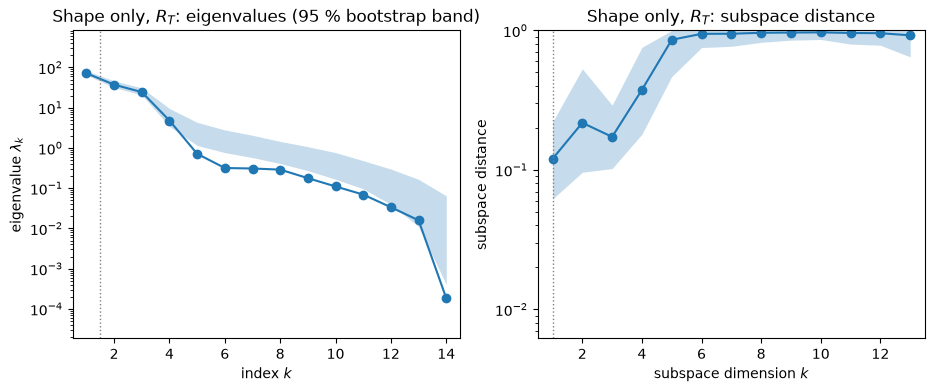

In [19]:
fig = eig_err_figure(ss, 'Shape only, $R_T$')
fig

No run is flagged by either rule (friction ratio 1.0280–1.0409, largest $|z|$ 3.6; wave cut 0.568–1.081 of $R_w$), so all 256 runs are used. $R_T$ ranges from 44.56 to 75.29 N (parent hull 48.93 N), and 52 of the 256 hulls violate a geometric constraint. The spectrum has **no dominant first eigenvalue** ($\lambda_1/\lambda_2 = 1.92$, $\lambda_2/\lambda_3 = 1.53$; the eigenvalue-gap rule picks $n = 1$ by a small margin), **but a clear gap after the third** ($\lambda_3/\lambda_4 = 5.10$; the first three carry 0.512, 0.266 and 0.174 of the trace). The bootstrap agrees: the mean subspace distance is 0.12 for $k = 1$, 0.2177 for $k = 2$ and 0.1727 for $k = 3$, against 0.3753 for $k = 4$. The shape dependence of $R_T$ at the benchmark point is three-dimensional, and we use **three active variables** here: the gap after $\lambda_3$ is the only large one, the three-dimensional subspace is well determined, and the surrogates below need all three (LOO $R^2$ 0.51, 0.80 and 0.94 for one, two and three). As in the main study, the bootstrap ranges of the smallest eigenvalues lie above the estimates ($\lambda_5 = 0.715$ with range $[1.15, 4.34]$), the upward bias of resampling for small eigenvalues; they do not affect the choice.

w1: s4 +0.719, s2 +0.497, s1 +0.291, s3 -0.280, s8 -0.227
w2: s8 +0.535, s3 -0.533, s7 -0.385, s5 +0.267, s6 -0.237
against the shape block of the 16-input study: |w1 . w1| = 0.668; span(w1, w2) principal-angle cosines 0.964, 0.164
against the same, at Fr = 0.28, T = -6.16: |w1 . w1| = 0.812; span(w1, w2) principal-angle cosines 0.960, 0.079


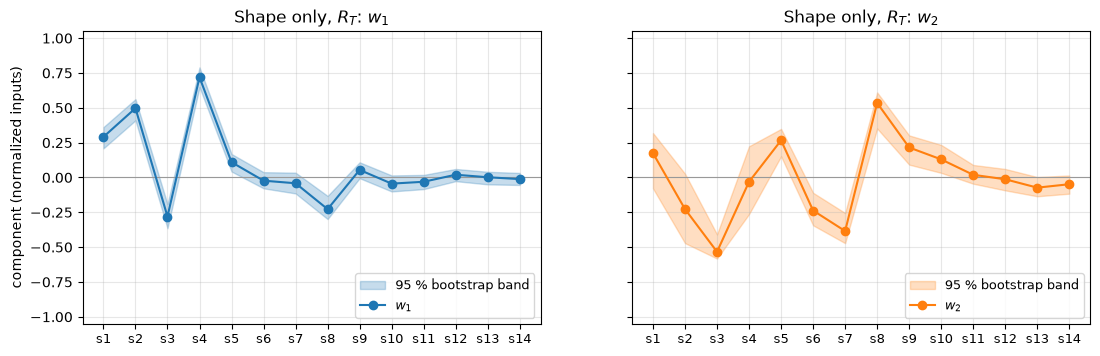

In [20]:
def vec_figure_s(s, title, labs):
    W = s.eigenvectors
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
    k = np.arange(len(labs))
    for i in range(2):
        B = s.bootstrap_eigenvectors[:, :, i]
        lo, hi = np.percentile(B, [2.5, 97.5], axis=0)
        axs[i].axhline(0, color='0.6', lw=0.8)
        axs[i].fill_between(k, lo, hi, color=f'C{i}', alpha=0.25, label='95 % bootstrap band')
        axs[i].plot(k, W[:, i], 'o-', color=f'C{i}', label=f'$w_{i + 1}$')
        axs[i].set_xticks(k, labs, fontsize=9)
        axs[i].grid(True, alpha=0.3)
        axs[i].legend(loc='lower right', fontsize=9)
        axs[i].set_title(f'{title}: $w_{i + 1}$')
    axs[0].set_ylim(-1.05, 1.05)
    axs[0].set_ylabel('component (normalized inputs)')
    plt.close(fig)
    return fig

fig = vec_figure_s(ss, 'Shape only, $R_T$', slabels)
Ws = ss.eigenvectors
for i in range(2):
    o = np.argsort(-np.abs(Ws[:, i]))[:5]
    print(f'w{i + 1}: ' + ', '.join(f'{slabels[j]} {Ws[j, i]:+.3f}' for j in o))
for key, title in (('block', 'shape block of the 16-input study'), ('cond', 'same, at Fr = 0.28, T = -6.16')):
    W0 = blk[key][1]
    cos = np.linalg.svd(Ws[:, :2].T @ W0[:, :2])[1]
    print(f'against the {title}: |w1 . w1| = {abs(Ws[:, 0] @ W0[:, 0]):.3f}; span(w1, w2) principal-angle cosines '
          f'{cos[0]:.3f}, {cos[1]:.3f}')
fig

The leading shape direction is mode 4 +0.719, mode 2 +0.497, mode 1 +0.291, mode 3 −0.280 and mode 8 −0.227; the second is led by modes 8, 3, 7 and 5. The ordering of the modes by KLE variance is thus not the ordering of their effect on resistance: mode 4 outweighs modes 1 and 2. Against the shape block of the 16-input study, $|w_1\cdot w_1| = 0.668$ (0.812 for the block at Fr = 0.28, T = −6.16), and the two-dimensional spans share one direction (principal-angle cosine 0.964) but not the second (0.164): the 16-input design found roughly the first shape direction and missed the rest, as its bootstrap distance of 0.36 warned.

y1 range [-1.576, 1.580]; parent hull (s = 0) at y = (0, 0); optimized hull at (y1, y2) = (-0.782, 1.058); |s_opt| = 2.322, share of |s_opt|^2 along w1 0.114, along span(w1, w2) 0.321, along span(w1, w2, w3) 0.391; y3 = -0.614
w3: s2 +0.561, s4 -0.521, s1 +0.429, s6 +0.284, s8 +0.226
 n degree     R^2  LOO R^2  parent (N)  optimized (N)
 1      2  0.5235   0.5110       52.12          51.68
 1      3  0.5252   0.5088       52.12          51.57
 2      2  0.8089   0.8001       51.24          46.88
 2      3  0.8100   0.7942       51.24          46.77
 3      2  0.9462   0.9405       49.59          45.59
G7 values: parent 48.93 N, optimized hull 42.33 N (a 13.5 % reduction, 6.60 N); the quadratic in three active variables predicts a reduction of 4.00 N
global quadratic in the 14 shape inputs: in-sample R^2 0.9862


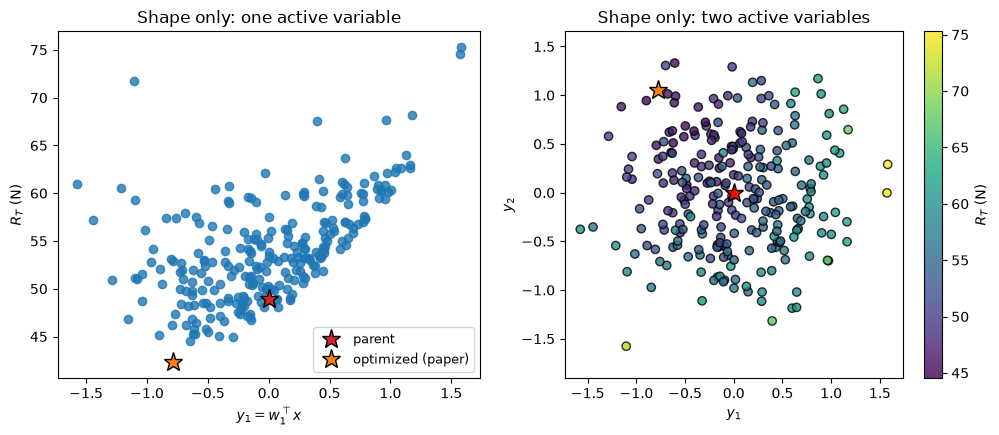

In [21]:
s_opt = REF[(REF[:, 0] == 1) & (REF[:, 1] == 7)][0, 4:18]   # the paper's optimized hull (App. A.4.1)
R7 = {int(r[0]): r[18] for r in REF if int(r[1]) == 7}       # G7: parent (0) and optimized hull (1)
y_opt = s_opt @ Ws[:, :2]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(ss, X=SXk, f=sRTk, dims=1, qoi_label='$R_T$ (N)', ax=a1)
ac.plotting.plot_sufficient_summary(ss, X=SXk, f=sRTk, dims=2, qoi_label='$R_T$ (N)', ax=a2,
                                    scatter_kw={'cmap': 'viridis', 'edgecolors': 'k'})
for a, y, r in ((a1, (0.0, R7[0]), 'parent'), (a1, (y_opt[0], R7[1]), 'optimized (paper)')):
    a.plot(*y, marker='*', ms=14, mec='k', color='C3' if r == 'parent' else 'C1', ls='', label=r)
a1.legend(fontsize=9)
a2.plot(0, 0, 'r*', ms=14, mec='k'); a2.plot(*y_opt, '*', color='C1', ms=14, mec='k')
a1.set_title('Shape only: one active variable'); a2.set_title('Shape only: two active variables')
plt.close(fig)
Ys = SXk @ Ws[:, :2]
print(f'y1 range [{Ys[:, 0].min():.3f}, {Ys[:, 0].max():.3f}]; parent hull (s = 0) at y = (0, 0); '
      f'optimized hull at (y1, y2) = ({y_opt[0]:.3f}, {y_opt[1]:.3f}); |s_opt| = {np.linalg.norm(s_opt):.3f}, '
      f'share of |s_opt|^2 along w1 {y_opt[0] ** 2 / (s_opt @ s_opt):.3f}, along span(w1, w2) {(y_opt @ y_opt) / (s_opt @ s_opt):.3f}, '
      f'along span(w1, w2, w3) {np.sum((s_opt @ Ws[:, :3]) ** 2) / (s_opt @ s_opt):.3f}; y3 = {s_opt @ Ws[:, 2]:.3f}')
w3 = Ws[:, 2]
o = np.argsort(-np.abs(w3))[:5]
print('w3: ' + ', '.join(f'{slabels[j]} {w3[j]:+.3f}' for j in o))
rows_s = []
for n, deg in [(1, 2), (1, 3), (2, 2), (2, 3), (3, 2)]:
    sg = ac.fit_surrogate(X=SXk, f=sRTk, subspace=ac.with_dimension(ss, n=n), kind='poly', degree=deg)
    r2 = 1 - sg.residuals @ sg.residuals / ((sRTk - sRTk.mean()) @ (sRTk - sRTk.mean()))
    pred = ac.predict(sg, np.vstack([np.zeros(ms), s_opt]))
    rows_s.append((n, deg, r2, sg.loo_r_squared, pred[0], pred[1]))
print(f"{'n':>2s} {'degree':>6s} {'R^2':>7s} {'LOO R^2':>8s} {'parent (N)':>11s} {'optimized (N)':>14s}")
for n, deg, r2, loo, p0, p1 in rows_s:
    print(f'{n:2d} {deg:6d} {r2:7.4f} {loo:8.4f} {p0:11.2f} {p1:14.2f}')
print(f'G7 values: parent {R7[0]:.2f} N, optimized hull {R7[1]:.2f} N (a {100 * (1 - R7[1] / R7[0]):.1f} % reduction, '
      f'{R7[0] - R7[1]:.2f} N); the quadratic in three active variables predicts a reduction of {rows_s[-1][4] - rows_s[-1][5]:.2f} N')
Qs = np.column_stack([np.ones(Msk), SXk] + [SXk[:, i] * SXk[:, j] for i in range(ms) for j in range(i, ms)])
rq = sRTk - Qs @ np.linalg.lstsq(Qs, sRTk, rcond=None)[0]
print(f'global quadratic in the 14 shape inputs: in-sample R^2 {1 - rq @ rq / ((sRTk - sRTk.mean()) @ (sRTk - sRTk.mean())):.4f}')
fig

One active variable explains only half of the variation (LOO $R^2 = 0.5110$ for a quadratic), two explain 0.8001 and three 0.9405, close to the global quadratic in all 14 inputs ($R^2 = 0.9862$ in-sample). The paper's optimized hull (stars; 42.33 N on G7, a 13.5 % reduction from the parent) lies at $y_1 = -0.782$, on the low-resistance side of the first active variable, but only 11.4 % of $\|\mathbf s_{\rm opt}\|^2$ lies along $w_1$, 32.1 % in the span of $w_1, w_2$ and 39.1 % in that of $w_1, w_2, w_3$. The quadratic in three active variables predicts 45.59 N there and 49.59 N at the parent: it captures about half of the 6.60 N reduction (4.00 N), so the optimum also exploits directions outside the three-dimensional subspace, where the hull lies on a face of the box ($s_1 = -1$, its only coefficient at a bound) and the variation averaged over the box is small. The reduction runs partly, not mainly, along the active directions.

### What the coarse grid changes

The data use the coarsest grid, G7. Rows 0–5 were rerun on G3, the grid of the paper's Sec. 5.1 study; rows 0–127 (a full 128-point Sobol' net of the design), the seven flagged rows and the borderline row 71 on G6; and row 63 also on G7 (again) and G5. The next cell compares the G3 reruns and the G6 reruns of the flagged rows; the one after it uses the 128 G6 rows to check the active subspace itself, and the third reruns the paper's reference points.

In [22]:
# fidelity_check.csv: row, fidelity, R_T, g1..g4, R_w, R_f, S_wet, disp (rerun), R_T at fidelity 7
g3m = FC[:, 1] == 3
rows_all = FC[g3m, 0].astype(int)
print('rows rerun on G3:', rows_all, ' flagged by the friction rule:', rows_all[bad[rows_all]])
print('R_T fidelity 3 :', np.array2string(FC[g3m, 2], precision=3))
print('R_T fidelity 7 :', np.array2string(FC[g3m, -1], precision=3))
print('ratio f3/f7    :', np.array2string(FC[g3m, 2] / FC[g3m, -1], precision=4))
ok3 = ~bad[rows_all]                                          # the comparison uses the unflagged rows
rows_c, RT3, RT7 = rows_all[ok3], FC[g3m, 2][ok3], FC[g3m, -1][ok3]
ratio = RT3 / RT7
print(f'unflagged rows {rows_c}: ratio mean {ratio.mean():.4f}, range {ratio.min():.4f} .. {ratio.max():.4f}; '
      f'R_w ratio {np.array2string(FC[g3m, 7][ok3] / Rw[rows_c], precision=3)}, '
      f'R_f ratio {np.array2string(FC[g3m, 8][ok3] / Rf[rows_c], precision=4)}')
print(f'correlation of R_T between fidelities over these rows: {np.corrcoef(RT3, RT7)[0, 1]:.5f}; '
      f'same rank order: {np.array_equal(np.argsort(RT3), np.argsort(RT7))}')
# G6 reruns of the flagged rows and the borderline row 71 (a failed rerun is a row of NaN outputs)
g6 = FC[:, 1] == 6
print(f"\n{'row':>4s} {'flag':>5s} {'G6/G7 R_T':>10s} {'R_w':>7s} {'R_f':>7s}")
for r in FC[g6]:
    i = int(r[0])
    if not (bad[i] or i == 71):
        continue
    if np.isnan(r[2]):
        print(f'{i:4d} {str(bool(bad[i])):>5s}   G6 run failed (no output)')
        continue
    print(f'{i:4d} {str(bool(bad[i])):>5s} {r[2] / RT[i]:10.3f} {r[7] / Rw[i]:7.3f} {r[8] / Rf[i]:7.3f}')
for r in FC[FC[:, 0] == 63]:
    print(f'row 63 rerun on G{int(r[1])}: R_T {r[2]:.3f} N, R_w {r[7]:.3f} N, R_f {r[8]:.3f} N (stored on G7: {RT[63]:.3f} N)')

rows rerun on G3: [0 1 2 3 4 5]  flagged by the friction rule: [3]
R_T fidelity 3 : [ 46.078 101.126  78.846  52.67   86.533  87.267]
R_T fidelity 7 : [ 51.447 110.018  82.728  71.757  91.678  92.19 ]
ratio f3/f7    : [0.8956 0.9192 0.9531 0.734  0.9439 0.9466]
unflagged rows [0 1 2 4 5]: ratio mean 0.9317, range 0.8956 .. 0.9531; R_w ratio [0.762 0.824 0.858 0.89  0.866], R_f ratio [1.004  1.0048 1.0079 1.0045 1.0072]
correlation of R_T between fidelities over these rows: 0.99689; same rank order: True

 row  flag  G6/G7 R_T     R_w     R_f
  63  True      0.092   5.539   0.074
   3  True      0.778   0.601   0.953
  71 False      0.971   0.948   0.994
 189  True      0.825   0.536   0.978
 207  True      0.453   0.006   0.874
 305  True   G6 run failed (no output)
 323  True      1.129   1.597   1.032
 343  True      1.204   1.977   1.042
row 63 rerun on G7: R_T 354.965 N, R_w 1.187 N, R_f 353.779 N (stored on G7: 354.965 N)
row 63 rerun on G6: R_T 32.782 N, R_w 6.575 N, R_f 26.207 N

For the five unflagged rows, G3 gives 4.7–10.4 % less resistance than G7 (ratio 0.8956–0.9531, mean 0.9317), almost all of it in the wave resistance (G3/G7 ratio 0.762–0.890) while friction changes by less than 1 %. The ordering of the rows is preserved and the two grids correlate at 0.99689 over these rows. Flagged row 3 shows the failure mode: G7 gives 71.76 N against 52.67 N on G3, with twice the G3 wave resistance.

On G6 the flagged rows change by 13–91 % in $R_T$ (ratios 0.092–1.204), or fail (row 305), while the borderline row 71 ($z = 6.5$, kept) changes by 2.9 % (ratio 0.971). Rows 323 and 343 move up rather than down on G6 (ratios 1.129 and 1.204, with $R_w$ ×1.6 and ×2.0), and row 305 lies in the G6 band too. Row 63 gives the same value when rerun on G7, and plausible values on G5 and G6 (33.09 N and 32.78 N).

**Does the active subspace transfer to a finer grid?** Rows 0–127 of the design were rerun on G6. The 126 rows that are valid on both grids (rows 3 and 63 are flagged on G7) are too few for a 16-input quadratic (153 coefficients), so the check uses the least-squares (OLS) direction, which for G7 agrees with $w_1$ to $|w_1\cdot w_{ols}| = 0.9994$, and a linear model of the grid difference $d = R_{T,G6} - R_{T,G7}$: if $\nabla d$ is small, the matrix of G6, $\mathbf C + \bar{\mathbf g}\nabla d^T + \nabla d\,\bar{\mathbf g}^T + \nabla d\nabla d^T$ (with $\bar{\mathbf g}$ the mean gradient of the G7 quadratic), has nearly the same leading eigenvector.

128 rows on G6: 0 raised ([]), 0 flagged by the friction rule ([]), flagged on G7: [ 3 63]; used: 126
R_T G6/G7: mean 0.9650, sd 0.0203, range 0.9133 .. 1.0228; mean offset -2.61 N; correlation 0.99818
R_w G6/G7: 0.908 (median), R_f G6/G7: 0.9945 .. 1.0043
OLS directions on the same 126 rows: |cos| = 0.99951 (angle 1.80 deg); |w_ols(G7, these rows) . w1(377 rows)| = 0.9963
d = R_T(G6) - R_T(G7): mean -2.61 N, sd 1.74 N; linear fit R^2 0.270; |grad d| = 1.56 N against sqrt(lambda1) = 50.7 N
||Delta C||_2 = 91.1 against lambda1 - lambda2 = 2450.2; leading eigenvector of C + Delta C against w1: |cos| = 0.99961 (angle 1.61 deg); lambda1/lambda2 21.2 (G7: 21.6)


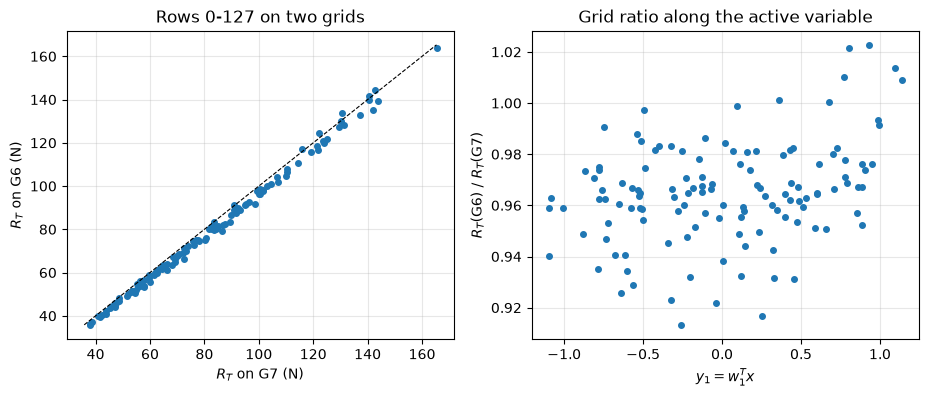

In [23]:
# Rows 0-127 (a full 128-point Sobol' net of the design) on G6 against G7
G6 = {int(r[0]): r for r in FC[FC[:, 1] == 6] if r[0] < 128}
rows6 = np.array(sorted(G6))
F6 = np.array([G6[i][2:11] for i in rows6])                 # R_T, g1..g4, R_w, R_f, S_wet, disp on G6
fail6 = ~np.isfinite(F6[:, 0])
U6 = X[rows6, 0] * np.sqrt(g * Lpp)
r6 = F6[:, 6] / (0.5 * rho * U6 ** 2 * F6[:, 7]) / (0.075 / (np.log10(U6 * Lpp / nu) - 2) ** 2)
k6 = np.zeros(len(rows6), bool)
k6[~fail6], z6 = friction_flags(X[rows6][~fail6], r6[~fail6], 8.0)
use = k6 & keep[rows6]                                       # valid on both grids
print(f'{len(rows6)} rows on G6: {int(fail6.sum())} raised ({rows6[fail6]}), {int((~fail6 & ~k6).sum())} flagged by the friction rule '
      f'({rows6[~fail6 & ~k6]}), flagged on G7: {rows6[bad[rows6]]}; used: {int(use.sum())}')
RT6, RT7 = F6[use, 0], RT[rows6[use]]
rat = RT6 / RT7
print(f'R_T G6/G7: mean {rat.mean():.4f}, sd {rat.std(ddof=1):.4f}, range {rat.min():.4f} .. {rat.max():.4f}; '
      f'mean offset {np.mean(RT6 - RT7):.2f} N; correlation {np.corrcoef(RT6, RT7)[0, 1]:.5f}')
print(f'R_w G6/G7: {np.median(F6[use, 5] / Rw[rows6[use]]):.3f} (median), R_f G6/G7: '
      f'{np.min(F6[use, 6] / Rf[rows6[use]]):.4f} .. {np.max(F6[use, 6] / Rf[rows6[use]]):.4f}')
Z6 = Z[rows6[use]]
A6 = np.column_stack([np.ones(len(Z6)), Z6])
b6 = np.linalg.lstsq(A6, RT6, rcond=None)[0][1:]
b7 = np.linalg.lstsq(A6, RT7, rcond=None)[0][1:]
ang = np.degrees(np.arccos(min(1.0, abs(b6 @ b7) / np.linalg.norm(b6) / np.linalg.norm(b7))))
print(f'OLS directions on the same {len(Z6)} rows: |cos| = {abs(b6 @ b7) / np.linalg.norm(b6) / np.linalg.norm(b7):.5f} '
      f'(angle {ang:.2f} deg); |w_ols(G7, these rows) . w1(377 rows)| = {abs(b7 @ res["R_T"].eigenvectors[:, 0]) / np.linalg.norm(b7):.4f}')
# the difference d = R_T(G6) - R_T(G7), fitted linearly; its effect on C = E[grad f grad f^T]
d = RT6 - RT7
cd, *_ = np.linalg.lstsq(A6, d, rcond=None)
rd = d - A6 @ cd
gd_ = cd[1:]
print(f'd = R_T(G6) - R_T(G7): mean {d.mean():.2f} N, sd {d.std(ddof=1):.2f} N; linear fit R^2 {1 - rd @ rd / ((d - d.mean()) @ (d - d.mean())):.3f}; '
      f'|grad d| = {np.linalg.norm(gd_):.2f} N against sqrt(lambda1) = {np.sqrt(res["R_T"].eigenvalues[0]):.1f} N')
gbar = gq                                                    # mean gradient of the G7 quadratic over the box
C6 = C16 + np.outer(gbar, gd_) + np.outer(gd_, gbar) + np.outer(gd_, gd_)
l6, W6 = eigsort(C6)
l7, W7 = eigsort(C16)
print(f'||Delta C||_2 = {np.linalg.norm(C6 - C16, 2):.1f} against lambda1 - lambda2 = {l7[0] - l7[1]:.1f}; '
      f'leading eigenvector of C + Delta C against w1: |cos| = {abs(W6[:, 0] @ W7[:, 0]):.5f} '
      f'(angle {np.degrees(np.arccos(min(1, abs(W6[:, 0] @ W7[:, 0])))):.2f} deg); lambda1/lambda2 {l6[0] / l6[1]:.1f} (G7: {l7[0] / l7[1]:.1f})')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(RT7, RT6, 'o', ms=4)
lim = [min(RT7.min(), RT6.min()), max(RT7.max(), RT6.max())]
a1.plot(lim, lim, 'k--', lw=0.8)
a1.set_xlabel('$R_T$ on G7 (N)'); a1.set_ylabel('$R_T$ on G6 (N)'); a1.set_title('Rows 0-127 on two grids')
a2.plot(Z6 @ res['R_T'].eigenvectors[:, 0], rat, 'o', ms=4)
a2.set_xlabel('$y_1 = w_1^T x$'); a2.set_ylabel('$R_T$(G6) / $R_T$(G7)'); a2.set_title('Grid ratio along the active variable')
for a in (a1, a2):
    a.grid(True, alpha=0.3)
plt.close(fig)
fig

G6 gives on average 3.5 % less $R_T$ than G7 on these rows (ratio mean 0.9650, sd 0.0203, mean offset −2.61 N), but the ratio ranges from 0.9133 to 1.0228, so on some rows G6 gives more; the two grids correlate at 0.99818, and nearly all of the change is in the wave resistance (median G6/G7 ratio 0.908; friction within 0.9945–1.0043). None of the 128 G6 runs raised or failed the friction rule. The OLS directions of the two grids on the same 126 rows differ by 1.80° ($|\cos| = 0.99951$). The grid difference is small and only weakly linear (sd 1.74 N, linear $R^2 = 0.270$, $\|\nabla d\| = 1.56$ N against $\sqrt{\lambda_1} = 50.7$ N), so the matrix changes by $\|\Delta\mathbf C\|_2 = 91.1$, far below the gap $\lambda_1 - \lambda_2 = 2450.2$: **the leading eigenvector moves by 1.61°**, and $\lambda_1/\lambda_2$ is 21.2 instead of 21.6. The one-dimensional result is thus not an artefact of the coarse grid between G7 and G6; we did not repeat the check on G3 or G1, where the bias is larger (above) and its variation over the box unknown.

In [24]:
# reference_runs.csv: hull (0 parent, 1 optimized), fidelity, 16 inputs, 9 outputs, cpu_s, wall_s
pellegrini = {1: 41.5, 2: 41.8, 3: 42.3, 4: 43.5, 5: 44.4, 6: 45.3, 7: 48.9}   # Pellegrini et al. 2022, Table 2
print(f"{'hull':8s} {'fid':>3s} {'R_T (N)':>10s} {'R_w (N)':>9s} {'R_f (N)':>9s} {'paper (N)':>10s} {'wall (s)':>9s}")
for r in REF:
    hull, fid = int(r[0]), int(r[1])
    rt, rw, rf = r[18], r[23], r[24]
    paper = f'{pellegrini[fid]:.1f}' if hull == 0 else ('36.3116' if fid == 1 else 'not rep.')
    print(f"{['parent', 'optimum'][hull]:8s} {fid:3d} {rt:10.4f} {rw:9.4f} {rf:9.4f} {paper:>10s} {r[-1]:9.2f}")
ref = {(int(r[0]), int(r[1])): r[18] for r in REF}
wall = {(int(r[0]), int(r[1])): r[-1] for r in REF}             # wall time of each run, s
print(f'cost of the parent hull, G1 against G7: wall {wall[0, 1]:.2f} s / {wall[0, 7]:.2f} s = {wall[0, 1] / wall[0, 7]:.0f}x '
      f'(paper normalized costs 1.00 / 0.03 = {1.00 / 0.03:.0f}x, App. A.4.1)')
rep = REF[:, -1] / REF[:, -2]                                  # wall time / the code's own time report
print(f"wall time / the time the code reports (elapsed_CPUtime.out): {rep.min():.2f} .. {rep.max():.2f} over the {len(REF)} runs")
print(f'optimized hull: R_T reduction against the parent {100 * (1 - ref[1, 1] / ref[0, 1]):.2f} % at fidelity 1, '
      f'{100 * (1 - ref[1, 7] / ref[0, 7]):.2f} % at fidelity 7 (paper: 12.5 %, App. A.4.1)')
zopt = 2 * (REF[REF[:, 0] == 1][0, 2:18] - gd.LOWER) / (gd.UPPER - gd.LOWER) - 1
print(f'optimized hull on the active variables of R_T (Fr, T fixed): (y1, y2) = '
      f'({zopt @ res["R_T"].eigenvectors[:, 0]:.3f}, {zopt @ res["R_T"].eigenvectors[:, 1]:.3f}) against the parent '
      f'({z0 @ res["R_T"].eigenvectors[:, 0]:.3f}, {z0 @ res["R_T"].eigenvectors[:, 1]:.3f})')
# App. A.3.3: E[R] with Fr and T uniform, s = 0, fidelity 6
ER = QD[:, 2] @ QD[:, 3]
print(f'E[R_T], Fr and T uniform, s = 0, fidelity 6: {ER:.4f} N by a 6 x 3 Gauss-Legendre rule '
      f'(paper: 68.3987 N, 181-point sparse grid); relative difference {ER / 68.398655639653271 - 1:+.2e}')

hull     fid    R_T (N)   R_w (N)   R_f (N)  paper (N)  wall (s)
parent     7    48.9338   16.6285   32.3053       48.9      2.87
parent     6    45.3275   12.9707   32.3568       45.3      5.06
parent     5    44.4149   12.0092   32.4057       44.4      9.81
parent     4    43.4719   11.0491   32.4228       43.5     30.81
parent     3    42.3003    9.8539   32.4465       42.3     62.20
parent     1    41.5015    9.0307   32.4707       41.5    432.87
optimum    7    42.3291   10.2822   32.0469   not rep.      4.94
optimum    1    36.3116    4.0717   32.2399    36.3116    453.38
cost of the parent hull, G1 against G7: wall 432.87 s / 2.87 s = 151x (paper normalized costs 1.00 / 0.03 = 33x, App. A.4.1)
wall time / the time the code reports (elapsed_CPUtime.out): 10.00 .. 10.10 over the 8 runs
optimized hull: R_T reduction against the parent 12.51 % at fidelity 1, 13.50 % at fidelity 7 (paper: 12.5 %, App. A.4.1)
optimized hull on the active variables of R_T (Fr, T fixed): (y1, y2) = (-0.

The parent hull reproduces Pellegrini et al.'s Table 2 [[4]](https://doi.org/10.3390/math10030481) on every grid run (48.93, 45.33, 44.41, 43.47, 42.30 and 41.50 N against 48.9, 45.3, 44.4, 43.5, 42.3 and 41.5 N), and the UM-Bridge test value on G7 to all printed digits. The optimized hull of App. A.4.1 gives **36.3116 N on G1, the paper's value**, a 12.51 % reduction (paper: 12.5 %); on G7 the same hull gives 42.33 N, a 13.50 % reduction, so the coarse grid ranks the two hulls correctly. On the active variables of the 16-input study the optimized hull moves from $(y_1, y_2) = (-0.600, 0.076)$ to $(-0.764, -0.538)$; the shape-only study above locates it better. For the uniform $(\mathrm{Fr}, T)$ case of App. A.3.3 (G6, parent hull) a 6 × 3 Gauss–Legendre rule gives E[R] = 68.4442 N against the paper's 68.3987 N from a 181-point sparse grid, a difference of 0.067 %; we did not estimate the error of either rule. The 18 quadrature runs store only $R_T$, so the per-run failure rule could not be applied to them; their shallowest draft node, −5.683 m, lies 0.033 m below the G6 band, which was mapped at Fr = 0.28 only.

**Cost** (wall time on the shared 2-CPU machine that wrote the files): the parent hull took 2.87 s on G7, 62.20 s on G3 and 432.87 s on G1, so G1 costs **151** times G7; the paper's normalized costs (1.00 and 0.03, a ratio of 33) were measured differently. The paper's 30–35 s per evaluation (G3, Sec. 5.1.3) is per container call on one physical CPU core of a cloud node, against 62.2 s here on a shared machine. The time the code writes to `elapsed_CPUtime.out` is a tenth of the wall time in every run (ratio 10.00–10.10) and is not used: the program reads `SYSTEM_CLOCK`, a wall clock despite the file's label "Elapsed CPU time", and divides the count by 10000, while gfortran's default clock counts 1000 per second (`src/main.f90` of L2-Sea, lines 23–24 and 73–78, commit 100da62).

### Comparison with the paper

The paper reports no active subspace or sensitivity analysis, so the comparison is with the reference values it gives for the model (App. A.3.3, A.4.1, Sec. 5.1.3), with UM-Bridge's own test value, and with Table 2 of Pellegrini et al. [[4]](https://doi.org/10.3390/math10030481), the grid study the paper cites ([20] there).

In [25]:
sT, sW = res['R_T'], res['R_w']
table = [
    ('R_T at parent hull, Fr 0.28, T -6.16, fidelity 7 (UM-Bridge test)', '48.9337769 N', f'{ref[0, 7]:.7f} N'),
    ('R_T at parent hull, fidelity 1 / 3 / 6 (Pellegrini Table 2)', '41.5 / 42.3 / 45.3 N',
     f'{ref[0, 1]:.2f} / {ref[0, 3]:.2f} / {ref[0, 6]:.2f} N'),
    ('R_T at the optimized hull, fidelity 1 (App. A.4.1)', '36.3116 N', f'{ref[1, 1]:.4f} N'),
    ('Resistance reduction of the optimized hull', '12.5 %', f'{100 * (1 - ref[1, 1] / ref[0, 1]):.2f} % (fidelity 1)'),
    ('E[R], Fr and T uniform, s = 0, fidelity 6 (App. A.3.3)', '68.3987 N', f'{ER:.4f} N (Gauss-Legendre 6 x 3)'),
    ('Run time per evaluation', '30-35 s (fidelity 3, one core)',
     f'{wall[0, 3]:.1f} s wall at fidelity 3 (shared 2-CPU machine); {wall[0, 7]:.2f} s at fidelity 7'),
    ('Cost of G1 relative to G7', '1.00 / 0.03 (normalized, A.4.1)',
     f'{wall[0, 1] / wall[0, 7]:.0f}x (wall time, parent hull)'),
    ('Active subspace eigenvalues, R_T', 'not reported', f'lam1/lam2 = {sT.eigenvalues[0] / sT.eigenvalues[1]:.1f}'),
    ('Dominant input of R_T', 'not reported', f'Fr (|w1_Fr| = {abs(sT.eigenvectors[0, 0]):.3f})'),
    ('Active subspace eigenvalues, C_T', 'not reported', f'lam1/lam2 = {sCT.eigenvalues[0] / sCT.eigenvalues[1]:.2f}'),
    ('Shape-only R_T at Fr 0.28, T -6.16 (A.4.1 setting)', 'not reported',
     f'lam1/lam2 = {ss.eigenvalues[0] / ss.eigenvalues[1]:.2f}, lam3/lam4 = {ss.eigenvalues[2] / ss.eigenvalues[3]:.2f}'),
]
w = max(len(t[0]) for t in table)
print(f"{'quantity':{w}s}  {'paper':34s}  notebook")
for a, b, c in table:
    print(f'{a:{w}s}  {b:34s}  {c}')

quantity                                                           paper                               notebook
R_T at parent hull, Fr 0.28, T -6.16, fidelity 7 (UM-Bridge test)  48.9337769 N                        48.9337769 N
R_T at parent hull, fidelity 1 / 3 / 6 (Pellegrini Table 2)        41.5 / 42.3 / 45.3 N                41.50 / 42.30 / 45.33 N
R_T at the optimized hull, fidelity 1 (App. A.4.1)                 36.3116 N                           36.3116 N
Resistance reduction of the optimized hull                         12.5 %                              12.51 % (fidelity 1)
E[R], Fr and T uniform, s = 0, fidelity 6 (App. A.3.3)             68.3987 N                           68.4442 N (Gauss-Legendre 6 x 3)
Run time per evaluation                                            30-35 s (fidelity 3, one core)      62.2 s wall at fidelity 3 (shared 2-CPU machine); 2.87 s at fidelity 7
Cost of G1 relative to G7                                          1.00 / 0.03 (normalized, A.4.1)

The reference values the paper gives for the model are reproduced by the locally built code: the optimized hull of App. A.4.1 to all six printed digits, and the uniform-input expected value of App. A.3.3 to 0.067 % by a different quadrature rule (a 6 × 3 Gauss–Legendre rule against the paper's 181-point sparse grid). The grid values of Table 2 are those of Pellegrini et al., the paper the article cites, and agree to their one decimal. This confirms that the 16 inputs are passed as the UM-Bridge container passes them (Fr, the draft as `ztrasla`, the 14 coefficients) and that the settings are the benchmark's. The active-subspace results have no counterpart in the paper. They rest on the coarsest grid, which fails silently in a band of draft near $T \approx -5.61$ to $-5.68$ m (7 of 384 runs, excluded by a stated rule) and gives 5–12 % more resistance than G3 (G3 is 4.7–10.4 % lower); the one-dimensional subspace of $R_T$ transfers to G6 (1.6°) but is mostly the speed scaling ($\lambda_1/\lambda_2 = 1.87$ for $C_T$), and the shape dependence at the benchmark's operating point is three-dimensional.

### References

[1] L. Seelinger, A. Reinarz, M. B. Lykkegaard, R. Akers, A. M. A. Alghamdi, D. Aristoff, W. Bangerth, J. Bénézech, M. Diez, K. Frey, J. D. Jakeman, J. S. Jørgensen, K.-T. Kim, B. M. Kent, M. Martinelli, M. Parno, R. Pellegrini, N. Petra, N. A. B. Riis, K. Rosenfeld, A. Serani, L. Tamellini, U. Villa, T. J. Dodwell, and R. Scheichl. [Democratizing uncertainty quantification](https://doi.org/10.1016/j.jcp.2024.113542). *Journal of Computational Physics*, 521:113542, 2025. Model: [UM-Bridge benchmarks, L2-Sea](https://um-bridge-benchmarks.readthedocs.io/en/docs/models/l2-sea.html); code: [MAORG-CNR-INM/NATO-AVT-331-L2-Sea-Benchmark](https://github.com/MAORG-CNR-INM/NATO-AVT-331-L2-Sea-Benchmark) (A. Serani and M. Diez, GPL-3.0, doi:10.5281/zenodo.19351757).

[2] L. Seelinger, V. Cheng-Seelinger, A. Davis, M. Parno, and A. Reinarz. [UM-Bridge: Uncertainty quantification and modeling bridge](https://doi.org/10.21105/joss.04748). *Journal of Open Source Software*, 8(83):4748, 2023.

[3] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[4] R. Pellegrini, A. Serani, G. Liuzzi, F. Rinaldi, S. Lucidi, and M. Diez. [A derivative-free line-search algorithm for simulation-driven design optimization using multi-fidelity computations](https://doi.org/10.3390/math10030481). *Mathematics*, 10(3):481, 2022.

[5] A. Serani, F. Stern, E. F. Campana, and M. Diez. [Hull-form stochastic optimization via computational-cost reduction methods](https://doi.org/10.1007/s00366-021-01375-x). *Engineering with Computers*, 38(S3):2245–2269, 2022.

[R1]: https://doi.org/10.1016/j.jcp.2024.113542
[R2]: https://doi.org/10.21105/joss.04748
[R3]: https://doi.org/10.1137/1.9781611973860
[R4]: https://doi.org/10.3390/math10030481
[R5]: https://doi.org/10.1007/s00366-021-01375-x

### Acknowledgments

From the paper (p. 17–18): M. Diez, R. Pellegrini and A. Serani, the authors of the L2-Sea benchmark, were partially supported by the Office of Naval Research through NICOP grant N62909-21-1-2042, in collaboration with the NATO task group AVT-331 "Goal-driven, multi-fidelity approaches for military vehicle system-level design". The paper also acknowledges NSF (DMS-1818726, DMS-2111277, OAC-1835673, DMS-1821210, EAR-1925595), UK EPSRC (EP/S017038/1), the US DOE Office of Advanced Scientific Computing Research, Google Cloud Research Credits (GCP211124249), the Villum Foundation (25893), bwHPC and the DFG (INST 35/1597-1 FUGG, EXC 2181/1 - 390900948), and the European Union NextGenerationEU (202222PACR UQ-FLY; ICSC).

In [26]:
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

notebook run time: 15.2 s
